<a href="https://colab.research.google.com/github/AlaKh09/Mentalist/blob/Notebook/mentalist_part4NOUR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reditus — Segmentation des patients diabétiques et prédiction de la réadmission à 30 jours

*Projet de Data Science suivant la méthode **CRISP-DM** — dataset *Diabetes 130-US Hospitals (1999–2008)**

**Dataset :** 101 766 séjours hospitaliers de patients diabétiques, 50 variables, 130 hôpitaux américains.

| Phase CRISP-DM | Contenu du notebook |
|---|---|
| **0. État de l'art** | Travaux existants, repères de performance |
| **1. Business Understanding** | Objectifs métier (BO1, BO2) → objectifs Data Science (DSO) |
| **2. Data Understanding** | Structure, statistiques, valeurs manquantes, cible, distributions, outliers, corrélations, variables catégorielles, lien avec la cible, bilan qualité |
| **3. Data Preparation** | Valeurs manquantes, identifiants, variables (quasi) constantes, regroupement des diagnostics et spécialités, exclusion décès/hospice, cible, séparation train/test par patient, encodage, **équilibrage des classes**, **PCA sur les variables numériques** |
| **4. Modeling** | Clustering K-Means (BO2) ; classification arbre de décision et KNN avec équilibrage (BO1) |
| **5. Evaluation** | Qualité, stabilité et profils des clusters ; performance, seuil, interprétation et équité du classifieur ; verdict BO1/BO2 |
| **6. Deployment** | Plan de déploiement, simulation, sauvegarde des modèles, maintenance |

## 0. État de l'art

**Origine des données.** Le dataset est un extrait de 10 ans (1999–2008) de soins cliniques dans 130 hôpitaux américains (base Health Facts). Il a été analysé par Strack et al. (2014), qui ont étudié le lien entre la **mesure de l'HbA1c** à l'hôpital et la réadmission précoce, à l'aide d'une **régression logistique**. L'HbA1c n'était mesurée que dans 18,4 % des séjours. Le dataset est disponible sur l'UCI Machine Learning Repository.

**Pratiques courantes sur ce problème**
* **Modèles :** régression logistique (référence interprétable), arbres de décision, Random Forest et gradient boosting.
* **Performance :** la prédiction de la réadmission est réputée difficile ; les AUC rapportées se situent le plus souvent entre **0,6 et 0,7**, car des facteurs décisifs (soutien social, observance, suivi après la sortie) ne figurent pas dans les données.
* **Contexte :** aux États-Unis, le programme Medicare de réduction des réadmissions (HRRP) pénalise les hôpitaux ayant trop de réadmissions, d'où l'intérêt financier du sujet.

**Pièges fréquents :** patients répétés qui créent une fuite entre train et test, conservation des patients décédés ou en hospice (non réadmissibles), usage de l'accuracy malgré le déséquilibre des classes, codes diagnostics trop nombreux.

**Positionnement de Reditus**
* On évite ces pièges : séparation train / test **par patient**, exclusion des décès et des hospices, **équilibrage des classes** sur le train et métriques adaptées (recall, PR-AUC), regroupement des diagnostics.
* On **combine segmentation et prédiction** : la segmentation décrit *qui* sont les patients, la classification prédit *qui reviendra*.
* Repère de performance attendu : une ROC-AUC autour de 0,65.

**Références**
* Strack B., DeShazo J. P., Gennings C., Olmo J. L., Ventura S., Cios K. J., Clore J. N. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International, 2014, 781670. doi:10.1155/2014/781670
* Strack B. et al. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [dataset]. UCI Machine Learning Repository.

## 1. Business Understanding

### 1.0 Des objectifs métier (BO) aux objectifs Data Science (DSO)

| | Objectif métier (BO) | Objectif Data Science (DSO) |
|---|---|---|
| **BO1 — Classification** | Réduire les réadmissions évitables à 30 jours en ciblant le suivi sur les patients à haut risque | Prédire `readmitted == '<30'` à la sortie. Succès = bon **recall** et **PR-AUC** sur la classe minoritaire (~11 % de positifs) ; les 20 % de scores les plus élevés doivent capturer bien plus de 20 % des réadmissions |
| **BO2 — Segmentation** | Personnaliser les parcours de soins selon le type de séjour | Trouver **3 à 6 segments** interprétables (silhouette, Davies-Bouldin) et comparer leur risque de réadmission |

### 1.1 BO1 : réduire les réadmissions évitables à 30 jours

| Élément | Description |
|---|---|
| **Contexte** | Le diabète est une maladie chronique aux complications fréquentes. Les hôpitaux réadmettent régulièrement des patients diabétiques peu après leur sortie. |
| **Problème métier** | Une réadmission sous 30 jours signale souvent une sortie trop précoce ou un suivi insuffisant. Elle coûte cher à l'hôpital (lits, personnel, pénalités Medicare) et nuit au patient. |
| **Parties prenantes** | Direction de l'hôpital, médecins et infirmiers, coordinateurs de soins, patients. |
| **Objectif métier** | Identifier **à la sortie** les patients les plus à risque, pour concentrer les ressources de suivi limitées (appel, rendez-vous précoce, revue des médicaments). |
| **Critères de succès** | Le modèle classe mieux que le hasard ; les 20 % de patients les plus à risque contiennent une grande part des réadmissions ; recall élevé sur la classe 1. |
| **Tâche Data Science** | Classification binaire de `readmitted_30`. |
| **Contraintes et risques** | Fort déséquilibre des classes (~11 % de positifs) ; manquer un patient à risque coûte plus cher qu'un appel inutile ; le modèle est une aide au tri, pas une décision clinique ; l'équité (âge, origine, genre) doit être surveillée. |

### 1.2 BO2 : personnaliser les soins grâce à la segmentation

| Élément | Description |
|---|---|
| **Contexte** | Les séjours de patients diabétiques ne sont pas homogènes : un séjour court et simple n'a pas les mêmes besoins qu'un séjour long chez un patient âgé souvent hospitalisé. |
| **Problème métier** | Un protocole de sortie identique pour tous gaspille des ressources sur les cas simples et sert mal les cas complexes. |
| **Parties prenantes** | Responsables de parcours de soins, chefs de service, direction (allocation des ressources). |
| **Objectif métier** | Construire un petit nombre de **profils de séjours interprétables** et adapter le parcours de soins à chacun. |
| **Critères de succès** | 3 à 6 segments compréhensibles, assez grands pour être actionnables, différents par leurs besoins et leur risque de réadmission. |
| **Tâche Data Science** | Clustering K-Means sur les variables quantitatives (après PCA), puis profilage des segments, y compris leur taux de réadmission (utilisé uniquement *après* le clustering). |
| **Contraintes et risques** | Pas de vérité terrain : la qualité se juge par la silhouette, Davies-Bouldin, la stabilité et l'interprétabilité. |

**Lien entre les deux objectifs :** le BO2 décrit *qui* sont les patients, le BO1 prédit *qui reviendra*. Ensemble, ils permettent d'adapter le parcours par segment et de prioriser selon le score de risque.

## 2. Data Understanding

### 2.1 Importation des bibliothèques

In [ ]:
# Bibliothèques de manipulation des données et de visualisation
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")              # masque les avertissements non bloquants
pd.set_option("display.max_columns", None)     # affiche toutes les colonnes
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

TEXTE = ["object", "string"]   # types des colonnes texte (compatible pandas 2 et 3)
SEED = 42                      # graine aléatoire : résultats reproductibles
print("Bibliothèques importées.")

Bibliothèques importées.


### 2.2 Chargement du dataset

Dans Colab, si le fichier `diabetic_data.csv` n'est pas encore présent, une fenêtre permet de l'importer depuis l'ordinateur.

In [ ]:
FICHIER = "diabetic_data.csv"

# Import du fichier dans Colab s'il n'est pas déjà présent
if not os.path.exists(FICHIER):
    from google.colab import files
    files.upload()

df = pd.read_csv(FICHIER)
print("Nombre de lignes   :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Saving diabetic_data.csv to diabetic_data.csv
Nombre de lignes   : 101766
Nombre de colonnes : 50


### 2.3 Aperçu du dataset

In [ ]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


### 2.4 Structure du dataset : types, modalités et valeurs manquantes

Un seul tableau résume chaque variable : son type, son nombre de modalités, ses valeurs manquantes (`NaN`) et ses valeurs `?` (manquants cachés).

In [ ]:
structure = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "nb_modalites": df.nunique(),
    "nb_NaN": df.isna().sum(),
    "nb_?": (df == "?").sum(),
})
structure["%_manquants"] = ((structure["nb_NaN"] + structure["nb_?"]) / len(df) * 100).round(2)
display(structure)

,type,nb_modalites,nb_NaN,nb_?,%_manquants
encounter_id,int64,101766,0,0,0.00
patient_nbr,int64,71518,0,0,0.00
race,object,6,0,2273,2.23
gender,object,3,0,0,0.00
age,object,10,0,0,0.00
weight,object,10,0,98569,96.86
admission_type_id,int64,8,0,0,0.00
discharge_disposition_id,int64,26,0,0,0.00
admission_source_id,int64,17,0,0,0.00
time_in_hospital,int64,14,0,0,0.00


**Interprétation :** le dataset compte **101 766 séjours et 50 variables** : 13 numériques (dont les identifiants et 3 catégories codées en nombres) et 37 textuelles.
- Des valeurs manquantes sont **cachées sous forme de `?`** dans 7 variables (`weight`, `medical_specialty`, `payer_code`, `race`, diagnostics).
- `max_glu_serum` et `A1Cresult` ont des `NaN` : l'examen n'a pas été réalisé.
- Les diagnostics ont **717 à 790 codes différents** : il faudra les regrouper.

### 2.5 Catégorisation des variables

| Groupe | Variables |
|---|---|
| **Identifiants** | `encounter_id` (séjour), `patient_nbr` (patient) |
| **Démographie** | `race`, `gender`, `age` (tranches de 10 ans), `weight` |
| **Séjour** | `admission_type_id`, `discharge_disposition_id`, `admission_source_id` (catégories codées par des nombres), `time_in_hospital`, `payer_code`, `medical_specialty` |
| **Utilisation antérieure des soins** | `number_outpatient`, `number_emergency`, `number_inpatient` (sur l'année précédente) |
| **Diagnostics** | `diag_1`, `diag_2`, `diag_3` (codes CIM-9), `number_diagnoses` |
| **Examens et actes** | `num_lab_procedures`, `num_procedures`, `max_glu_serum`, `A1Cresult` |
| **Médicaments** | `num_medications`, 23 colonnes de médicaments (`metformin`, `insulin`…), `change`, `diabetesMed` |
| **Cible** | `readmitted` : `<30`, `>30`, `NO` |

### 2.6 Statistiques des variables numériques

In [ ]:
# Les 8 variables réellement quantitatives (les *_id sont des catégories codées)
vars_numeriques = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
]
stats = df[vars_numeriques].describe().T
stats["asymetrie (skew)"] = df[vars_numeriques].skew()
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,asymetrie (skew)
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0,1.13
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0,-0.24
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0,1.32
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0,1.33
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0,8.83
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0,22.86
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0,3.61
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0,-0.88


**Interprétation :**
- Un séjour dure en moyenne **4,4 jours** (1 à 14) avec **16 médicaments** et **43 examens de laboratoire**.
- Les visites antérieures (`number_outpatient`, `number_emergency`, `number_inpatient`) ont une **médiane de 0** et une asymétrie très forte (8,8 ; 22,9 ; 3,6) : la plupart des patients n'ont aucune visite, quelques-uns en ont beaucoup (jusqu'à 76 passages aux urgences).
- `num_lab_procedures` est presque symétrique.

### 2.7 Valeurs manquantes

,nb_manquants,%
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


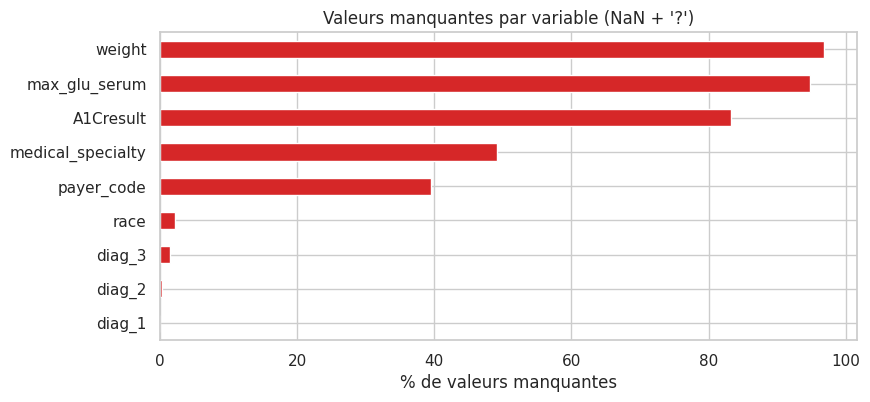

In [ ]:
# Valeurs manquantes = NaN + "?"
manquants = (df.isna().sum() + (df == "?").sum())
manquants = manquants[manquants > 0].sort_values(ascending=False)
pct = (manquants / len(df) * 100).round(2)
display(pd.DataFrame({"nb_manquants": manquants, "%": pct}))

plt.figure(figsize=(9, 4))
pct.plot(kind="barh", color="tab:red")
plt.gca().invert_yaxis()
plt.xlabel("% de valeurs manquantes")
plt.title("Valeurs manquantes par variable (NaN + '?')")
plt.show()

**Interprétation :**
- `weight` est manquant dans **96,9 %** des séjours : inexploitable.
- `max_glu_serum` (94,7 %) et `A1Cresult` (83,3 %) sont surtout « non mesurés » : l'absence d'examen est elle-même une information.
- `medical_specialty` (49,1 %) et `payer_code` (39,6 %) sont très incomplets mais utiles.
- `race` et les diagnostics ont peu de manquants (≤ 2,2 %).

### 2.8 Variable cible `readmitted`

,nb_sejours,%
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


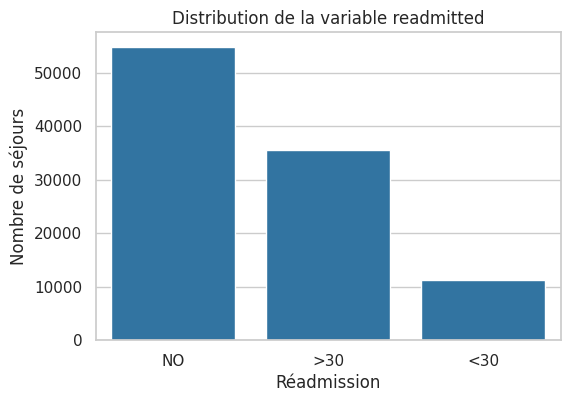

In [ ]:
cible = pd.DataFrame({
    "nb_sejours": df["readmitted"].value_counts(),
    "%": (df["readmitted"].value_counts(normalize=True) * 100).round(2),
})
display(cible)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], color="tab:blue")
plt.title("Distribution de la variable readmitted")
plt.xlabel("Réadmission"); plt.ylabel("Nombre de séjours")
plt.show()

**Interprétation :** seuls **11,16 %** des séjours sont suivis d'une réadmission en moins de 30 jours. C'est la classe qui nous intéresse, et elle est **minoritaire** (environ 1 séjour sur 9). Un modèle qui répondrait toujours « pas de réadmission » aurait déjà 89 % d'accuracy sans rien détecter : l'accuracy n'est donc **pas** un bon critère. On utilisera le recall et la PR-AUC.

### 2.9 Distributions des variables numériques

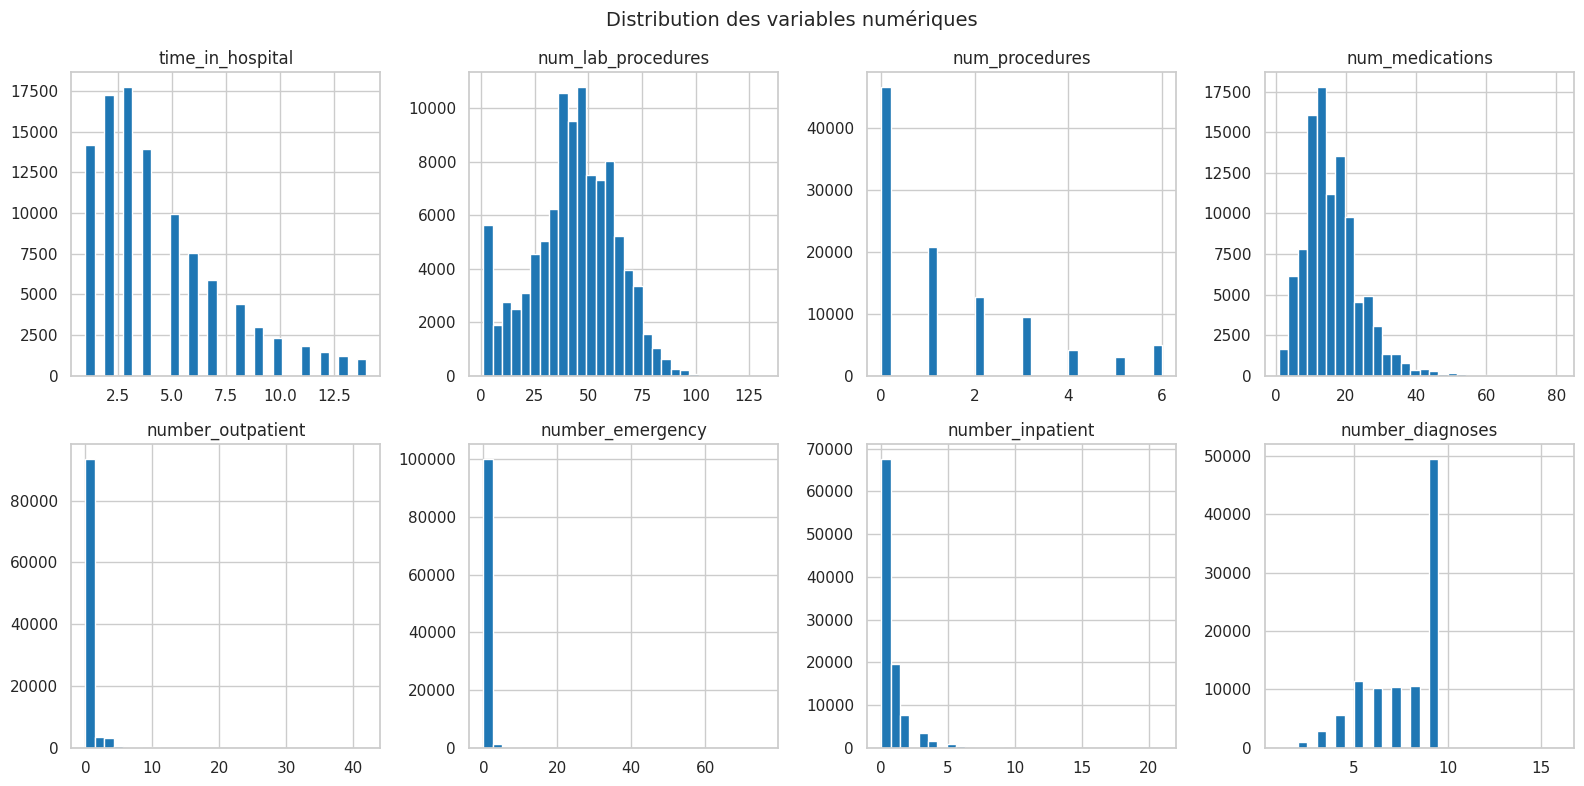

In [ ]:
df[vars_numeriques].hist(figsize=(16, 8), bins=30, layout=(2, 4), color="tab:blue")
plt.suptitle("Distribution des variables numériques", fontsize=14)
plt.tight_layout()
plt.show()

**Interprétation :** les distributions sont **asymétriques vers la droite** (beaucoup de petites valeurs, quelques grandes). Les visites antérieures sont concentrées à 0 : **84 %** des séjours n'ont aucune consultation externe, **89 %** aucun passage aux urgences et **66 %** aucune hospitalisation l'année précédente. `num_lab_procedures` suit une forme en cloche.

### 2.10 Valeurs aberrantes (outliers)

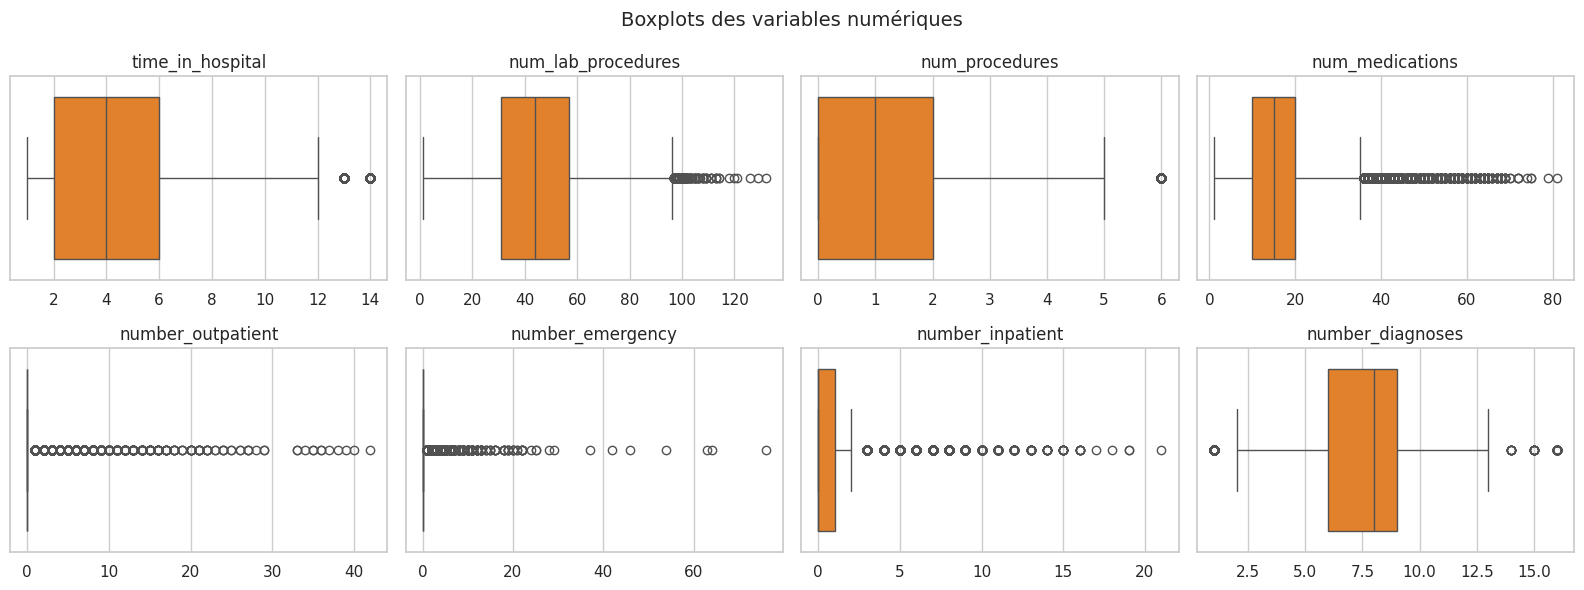

% de valeurs au-dessus de Q3 + 1,5 IQR :
time_in_hospital       2.21
num_lab_procedures     0.14
num_procedures         4.87
num_medications        2.51
number_outpatient     16.45
number_emergency      11.19
number_inpatient       6.93
number_diagnoses       0.06
dtype: float64


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), vars_numeriques):
    sns.boxplot(x=df[col], ax=ax, color="tab:orange")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boxplots des variables numériques", fontsize=14)
plt.tight_layout()
plt.show()

# Part d'observations au-delà de la borne haute Q3 + 1,5 x IQR
q1, q3 = df[vars_numeriques].quantile(0.25), df[vars_numeriques].quantile(0.75)
borne_haute = q3 + 1.5 * (q3 - q1)
print("% de valeurs au-dessus de Q3 + 1,5 IQR :")
print(((df[vars_numeriques] > borne_haute).mean() * 100).round(2))

**Interprétation :** les boxplots montrent de nombreuses valeurs extrêmes, surtout pour les visites antérieures (16,5 % des valeurs de `number_outpatient` dépassent la borne haute, car la médiane est 0). Ces valeurs sont **plausibles** (patients très suivis, séjours longs) : ce ne sont pas des erreurs. Elles seront **conservées**, et l'asymétrie sera réduite par `log1p` avant la PCA.

### 2.11 Corrélations entre variables numériques

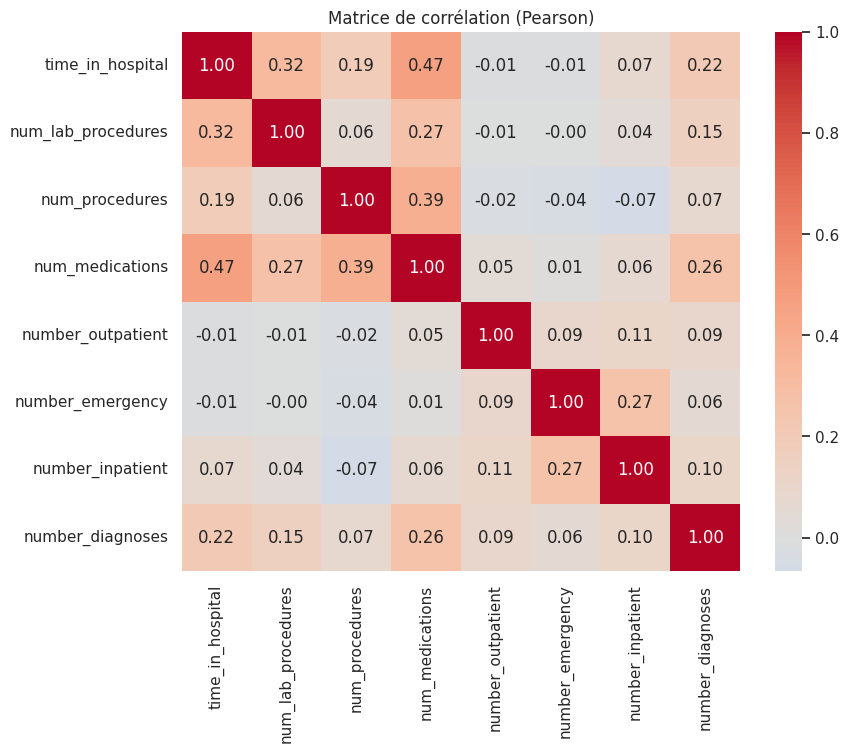

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[vars_numeriques].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation (Pearson)")
plt.show()

**Interprétation :** les corrélations sont **faibles à modérées**. Les plus fortes relient `time_in_hospital` et `num_medications` (0,47), `num_procedures` et `num_medications` (0,39), `time_in_hospital` et `num_lab_procedures` (0,32). Aucune variable n'est redondante : on les garde toutes.

### 2.12 Variables catégorielles : modalité dominante

Une variable dont presque toutes les valeurs sont identiques apporte très peu d'information.

In [ ]:
cols_texte = df.select_dtypes(include=TEXTE).columns
dominance = pd.DataFrame({
    "modalite_dominante": df[cols_texte].apply(lambda s: s.value_counts().index[0]),
    "%_dominante": (df[cols_texte].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(3),
    "nb_modalites": df[cols_texte].nunique(),
}).sort_values("%_dominante", ascending=False)
display(dominance)

print("Modalités de gender :")
print(df["gender"].value_counts())

,modalite_dominante,%_dominante,nb_modalites
examide,No,100.000,1
citoglipton,No,100.000,1
acetohexamide,No,99.999,2
metformin-pioglitazone,No,99.999,2
glimepiride-pioglitazone,No,99.999,2
metformin-rosiglitazone,No,99.998,2
troglitazone,No,99.997,2
glipizide-metformin,No,99.987,2
tolbutamide,No,99.977,2
miglitol,No,99.963,4


Modalités de gender :
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


**Interprétation :**
- **15 médicaments** ont plus de 99 % de séjours avec la même valeur (« No ») ; `examide` et `citoglipton` sont même **constants** (100 %). Ils n'apportent presque aucune information.
- `gender` contient **3 séjours `Unknown/Invalid`**, une valeur invalide.
- Les médicaments fréquents (`metformin`, `insulin`, `glipizide`…) sont assez variés pour être utiles.

### 2.13 Lien entre quelques variables et la cible

On crée temporairement une cible binaire (1 = réadmission en moins de 30 jours) pour observer le taux de réadmission selon l'âge, les hospitalisations antérieures et le type de sortie.

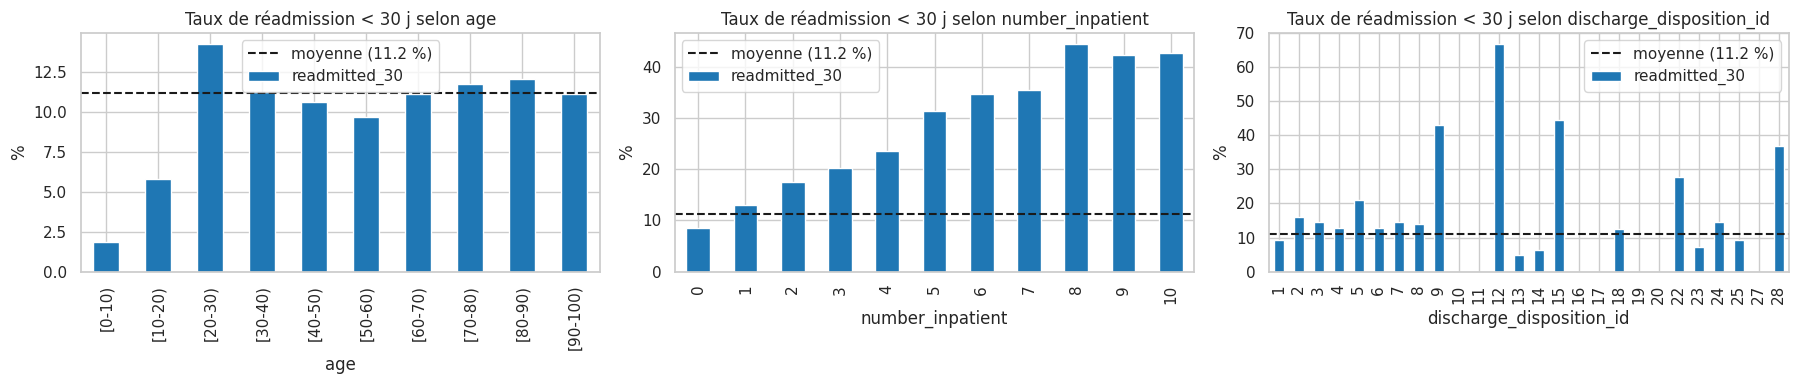

Taux de réadmission (%) pour les codes décès / hospice :
                          count  mean
discharge_disposition_id             
11                         1642  0.00
13                          399  4.76
14                          372  6.45
19                            8  0.00
20                            2  0.00


In [ ]:
df_tmp = df.copy()
df_tmp["readmitted_30"] = (df_tmp["readmitted"] == "<30").astype(int)
taux_moyen = df_tmp["readmitted_30"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["age", "number_inpatient", "discharge_disposition_id"]):
    taux = df_tmp.groupby(col)["readmitted_30"].mean() * 100
    if col == "number_inpatient":
        taux = taux.loc[:10]                      # au-delà de 10, trop peu de séjours
    taux.plot(kind="bar", ax=ax, color="tab:blue")
    ax.axhline(taux_moyen, ls="--", c="k", label=f"moyenne ({taux_moyen:.1f} %)")
    ax.set(title=f"Taux de réadmission < 30 j selon {col}", ylabel="%")
    ax.legend()
plt.tight_layout()
plt.show()

# Taux de réadmission des codes de sortie "décès / hospice"
deces_hospice = [11, 13, 14, 19, 20, 21]
print("Taux de réadmission (%) pour les codes décès / hospice :")
print((df_tmp[df_tmp["discharge_disposition_id"].isin(deces_hospice)]
       .groupby("discharge_disposition_id")["readmitted_30"].agg(["count", "mean"])
       .assign(mean=lambda t: (t["mean"] * 100).round(2))))

**Interprétation :**
- **Hospitalisations antérieures (`number_inpatient`) :** le taux de réadmission passe de **8,4 %** (aucune) à 12,9 % (une), 17,4 % (deux), puis **plus de 40 %** au-delà de 8. C'est le **signal le plus fort** du dataset.
- **Âge :** le taux est faible avant 20 ans (1,8 % et 5,8 %) et proche de la moyenne (≈ 11 %) ensuite.
- **Type de sortie :** les codes **décès** (11, 19, 20) ont **0 %** de réadmission et les codes **hospice** (13, 14) environ 5 % et 6 %. Ces séjours faussent la cible et seront exclus. Certains codes de transfert rares ont des taux élevés, mais sur de petits effectifs.

### 2.14 Bilan de la qualité des données

| # | Problème identifié | Traitement prévu (Data Preparation) |
|---|---|---|
| 1 | Valeurs manquantes cachées sous forme de `?` (`weight`, `medical_specialty`, `payer_code`, `race`, diagnostics) | Conversion en `NaN`, puis suppression (`weight`) ou catégorie `Unknown` (3.1) |
| 2 | `max_glu_serum` et `A1Cresult` absents dans la majorité des séjours | Catégorie `Not measured` : l'absence d'examen est une information (3.1) |
| 3 | `gender` contient 3 valeurs `Unknown/Invalid` | Suppression de ces 3 séjours (3.1) |
| 4 | Identifiants (`encounter_id`, `patient_nbr`) et patients répétés | Suppression de `encounter_id` ; `patient_nbr` gardé pour une séparation train/test par patient (3.2, 3.10) |
| 5 | Variables constantes ou quasi constantes (médicaments rares) | Suppression si la modalité dominante dépasse 99 % (3.3) |
| 6 | Forte cardinalité des diagnostics (≈ 700 codes) et des spécialités (73) | Regroupement CIM-9 et regroupement des spécialités rares (3.4, 3.5) |
| 7 | Variables numériques asymétriques avec valeurs extrêmes | Conservées ; transformation `log1p` pour la PCA (3.6, 3.13) |
| 8 | Séjours terminés par un décès (taux de réadmission de 0 %) ou un hospice (taux très faible) | Exclusion (3.7) |
| 9 | Cible déséquilibrée (classe `<30` minoritaire) | Équilibrage du train (SMOTE / sous-échantillonnage) et métriques adaptées (3.12, 4.2) |

## 3. Data Preparation

Toutes les transformations sont faites sur une copie (`df_clean`) pour garder les données originales intactes.

### 3.1 Traitement des valeurs manquantes et des valeurs invalides

In [ ]:
df_clean = df.copy()

# Les "?" sont des valeurs manquantes non reconnues par pandas : on les remplace par NaN
df_clean = df_clean.replace("?", np.nan)

manq = df_clean.isna().sum()
manq = manq[manq > 0].sort_values(ascending=False)
display(pd.DataFrame({"nb_manquants": manq, "%": (manq / len(df_clean) * 100).round(2)}))

,nb_manquants,%
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


**Stratégie par variable**

| Variable | % manquants | Décision | Justification |
|---|---|---|---|
| `weight` | 96,9 % | Suppression | Trop peu de valeurs pour être exploitable |
| `max_glu_serum`, `A1Cresult` | 94,7 % / 83,3 % | Catégorie `Not measured` | L'absence d'examen est une information médicale ; on n'invente pas de résultat |
| `medical_specialty`, `payer_code` | 49,1 % / 39,6 % | Catégorie `Unknown` | Variables utiles ; imputer une valeur précise serait arbitraire |
| `race`, `diag_1`, `diag_2`, `diag_3` | < 2,3 % | Catégorie `Unknown` | Garde les séjours sans attribuer une catégorie existante |
| `gender` = `Unknown/Invalid` | 3 séjours | Suppression des lignes | Valeur invalide, catégorie inutile pour les modèles |

In [ ]:
# 1) weight : trop de valeurs manquantes -> suppression de la colonne
df_clean = df_clean.drop(columns=["weight"])

# 2) Résultats d'examens : l'absence de mesure devient une catégorie
for col in ["max_glu_serum", "A1Cresult"]:
    df_clean[col] = df_clean[col].fillna("Not measured")

# 3) Variables catégorielles : catégorie "Unknown"
for col in ["race", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

# 4) gender : suppression des 3 séjours "Unknown/Invalid"
n_avant = len(df_clean)
df_clean = df_clean[df_clean["gender"] != "Unknown/Invalid"].reset_index(drop=True)

print("Séjours supprimés (gender invalide) :", n_avant - len(df_clean))
print("Valeurs manquantes restantes        :", df_clean.isna().sum().sum())
print("Dimensions                          :", df_clean.shape)

Séjours supprimés (gender invalide) : 3
Valeurs manquantes restantes        : 0
Dimensions                          : (101763, 49)


**Interprétation :** `weight` est supprimée, les manquants sont remplacés par `Not measured` ou `Unknown`, et les **3 séjours `gender` invalides** sont supprimés. Il ne reste **aucune valeur manquante** : **101 763 séjours, 49 colonnes**.

### 3.2 Identifiants et séjours multiples

In [ ]:
visites = df_clean.groupby("patient_nbr").size()
print("Séjours                        :", len(df_clean))
print("Patients uniques               :", df_clean["patient_nbr"].nunique())
print("Patients avec plusieurs séjours:", (visites > 1).sum())
print("Nombre maximal de séjours      :", visites.max())

# encounter_id identifie seulement le séjour : aucune information médicale -> suppression
# patient_nbr est gardé pour séparer train/test par patient (il ne sera pas une variable explicative)
df_clean = df_clean.drop(columns=["encounter_id"])
print("Dimensions :", df_clean.shape)

Séjours                        : 101763
Patients uniques               : 71515
Patients avec plusieurs séjours: 16773
Nombre maximal de séjours      : 40
Dimensions : (101763, 48)


**Interprétation :** les 101 763 séjours correspondent à **71 515 patients**. **16 773 patients** ont plusieurs séjours (jusqu'à 40). Si un même patient se retrouvait à la fois dans le train et le test, le modèle « reconnaîtrait » ce patient : c'est pourquoi la séparation train/test se fera **par patient** (3.10). `encounter_id` est supprimé.

### 3.3 Variables constantes et quasi constantes

Une variable est supprimée si sa modalité dominante représente **plus de 99 %** des séjours (100 % = constante).

In [ ]:
cols_texte = df_clean.select_dtypes(include=TEXTE).columns.drop("readmitted")
dominance = df_clean[cols_texte].apply(lambda s: s.value_counts(normalize=True).iloc[0])

constantes = dominance[dominance == 1].index.tolist()
quasi_constantes = dominance[(dominance > 0.99) & (dominance < 1)].index.tolist()

print("Variables constantes      :", constantes)
print("Variables quasi constantes:")
print((dominance[quasi_constantes] * 100).round(3).sort_values(ascending=False))

df_clean = df_clean.drop(columns=constantes + quasi_constantes)
print("\nVariables supprimées :", len(constantes) + len(quasi_constantes))
print("Dimensions           :", df_clean.shape)

Variables constantes      : ['examide', 'citoglipton']
Variables quasi constantes:
acetohexamide               99.999
glimepiride-pioglitazone    99.999
metformin-pioglitazone      99.999
metformin-rosiglitazone     99.998
troglitazone                99.997
glipizide-metformin         99.987
tolbutamide                 99.977
miglitol                    99.963
tolazamide                  99.962
chlorpropamide              99.915
acarbose                    99.697
nateglinide                 99.309
glyburide-metformin         99.306
dtype: float64

Variables supprimées : 15
Dimensions           : (101763, 33)


**Interprétation :** **15 variables supprimées** : 2 constantes (`examide`, `citoglipton`) et 13 quasi constantes (médicaments rarement prescrits et combinaisons de médicaments). Les 8 médicaments fréquents sont conservés. Le dataset passe de 48 à **33 colonnes**.

### 3.4 Regroupement des codes de diagnostic

`diag_1` (diagnostic principal), `diag_2` et `diag_3` (diagnostics secondaires) sont des codes de la **classification internationale des maladies (CIM-9 / ICD-9-CM)**, organisée en chapitres par appareil du corps. La partie entière indique la maladie, les décimales précisent le sous-type (`250.83` = diabète avec complication). Les codes **V** (facteurs de santé) et **E** (causes externes) ne sont pas des maladies.

Avec environ 700 à 790 codes par colonne, un encodage direct créerait plus de 2 000 colonnes. Nous reprenons le regroupement de **Strack et al. (2014)** :

| Groupe | Codes CIM-9 |
|---|---|
| Circulatory | 390–459, 785 |
| Respiratory | 460–519, 786 |
| Digestive | 520–579, 787 |
| Diabetes | 250.xx |
| Injury | 800–999 |
| Musculoskeletal | 710–739 |
| Genitourinary | 580–629, 788 |
| Neoplasms | 140–239 |
| Other | autres codes, codes V et E |
| Unknown | diagnostic non renseigné |

In [ ]:
for col in ["diag_1", "diag_2", "diag_3"]:
    print(f"{col} : {df_clean[col].nunique()} codes différents | exemples : {df_clean[col].head(8).tolist()}")

diag_1 : 717 codes différents | exemples : ['250.83', '276', '648', '8', '197', '414', '414', '428']
diag_2 : 749 codes différents | exemples : ['Unknown', '250.01', '250', '250.43', '157', '411', '411', '492']
diag_3 : 790 codes différents | exemples : ['Unknown', '255', 'V27', '403', '250', '250', 'V45', '250']


In [ ]:
def categorize_diagnosis(code):
    """Associe un code CIM-9 à une grande famille de maladies (Strack et al., 2014)."""
    if code == "Unknown":                       # diagnostic non renseigné
        return "Unknown"
    code = str(code)
    if code.startswith(("V", "E")):             # codes de situation ou de cause externe
        return "Other"
    code = float(code)                          # "250.83" -> 250.83
    if 250 <= code < 251:
        return "Diabetes"
    if 390 <= code <= 459 or code == 785:
        return "Circulatory"
    if 460 <= code <= 519 or code == 786:
        return "Respiratory"
    if 520 <= code <= 579 or code == 787:
        return "Digestive"
    if 800 <= code <= 999:
        return "Injury"
    if 710 <= code <= 739:
        return "Musculoskeletal"
    if 580 <= code <= 629 or code == 788:
        return "Genitourinary"
    if 140 <= code <= 239:
        return "Neoplasms"
    return "Other"


# Application aux trois colonnes, puis suppression des codes bruts
for col in ["diag_1", "diag_2", "diag_3"]:
    df_clean[col + "_group"] = df_clean[col].apply(categorize_diagnosis)
df_clean = df_clean.drop(columns=["diag_1", "diag_2", "diag_3"])

# Répartition (%) des groupes pour les trois diagnostics
repartition = pd.concat(
    {c: df_clean[c].value_counts(normalize=True) * 100 for c in ["diag_1_group", "diag_2_group", "diag_3_group"]},
    axis=1).round(1).sort_values("diag_1_group", ascending=False)
display(repartition)
print("Dimensions :", df_clean.shape)

,diag_1_group,diag_2_group,diag_3_group
Circulatory,29.9,31.3,29.8
Other,17.9,26.1,28.7
Respiratory,14.2,10.7,7.2
Digestive,9.3,4.1,3.9
Diabetes,8.6,12.6,16.9
Injury,6.9,2.4,1.9
Genitourinary,5.0,8.2,6.6
Musculoskeletal,4.9,1.7,1.9
Neoplasms,3.4,2.5,1.8
Unknown,0.0,0.4,1.4


Dimensions : (101763, 33)


**Interprétation :** chaque diagnostic passe d'environ **700 à 790 codes à 10 catégories** médicalement interprétables.
- Les **maladies circulatoires** sont le 1er groupe pour les trois diagnostics (≈ 30 %).
- Le **diabète** n'est le diagnostic principal que dans **8,6 %** des séjours, mais il apparaît plus souvent en diagnostic secondaire (12,6 % et 16,9 %) : les patients sont surtout hospitalisés pour une complication ou une autre maladie.
- `Other` reste important (18 à 29 %) car il regroupe beaucoup de maladies peu fréquentes et les codes V/E.

### 3.5 Regroupement des spécialités médicales rares

Les spécialités représentant moins de **0,1 %** des séjours sont regroupées dans `Other`. `Unknown` reste une catégorie à part.

In [ ]:
seuil = 0.001 * len(df_clean)
frequences = df_clean["medical_specialty"].value_counts()
rares = frequences[frequences < seuil].index

df_clean["medical_specialty_group"] = df_clean["medical_specialty"].where(
    ~df_clean["medical_specialty"].isin(rares), "Other")

print("Spécialités avant regroupement :", df_clean["medical_specialty"].nunique())
print("Spécialités rares regroupées   :", len(rares))
print("Spécialités après regroupement :", df_clean["medical_specialty_group"].nunique())
df_clean = df_clean.drop(columns=["medical_specialty"])

print("\nSpécialités les plus fréquentes (%) :")
print((df_clean["medical_specialty_group"].value_counts(normalize=True).head(8) * 100).round(1))

Spécialités avant regroupement : 73
Spécialités rares regroupées   : 46
Spécialités après regroupement : 28

Spécialités les plus fréquentes (%) :
medical_specialty_group
Unknown                   49.1
InternalMedicine          14.4
Emergency/Trauma           7.4
Family/GeneralPractice     7.3
Cardiology                 5.3
Surgery-General            3.0
Nephrology                 1.6
Orthopedics                1.4
Name: proportion, dtype: float64


**Interprétation :** les spécialités passent de **73 à 28 modalités** (46 spécialités rares regroupées dans `Other`). `Unknown` reste la plus fréquente (**49 %**) : l'information est incomplète. Parmi les spécialités renseignées dominent la médecine interne (14,4 %), les urgences (7,4 %), la médecine générale (7,3 %) et la cardiologie (5,3 %).

### 3.6 Variables numériques et valeurs aberrantes

`admission_type_id`, `discharge_disposition_id` et `admission_source_id` sont stockées comme des nombres mais représentent des **catégories** : elles seront encodées comme telles.

**Décision sur les valeurs extrêmes :** elles ne sont pas supprimées, car elles correspondent à des situations réelles (patient souvent hospitalisé, séjour long). Les trois variables de visites antérieures, très asymétriques (médiane 0, maximum jusqu'à 76), seront transformées par `log1p` avant la PCA (3.13).

In [ ]:
vars_categorielles_codees = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
print("Variables quantitatives       :", vars_numeriques)
print("Catégories codées en nombres  :", vars_categorielles_codees)

Variables quantitatives       : ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Catégories codées en nombres  : ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']


### 3.7 Exclusion des séjours non réadmissibles

Un patient décédé ne peut pas être réadmis, et un patient transféré en soins palliatifs (hospice) ne l'est presque jamais : garder ces séjours ajouterait des « 0 » artificiels à la cible (section 2.13 : 0 % de réadmission pour les décès, environ 5 % pour les hospices). Strack et al. (2014) les excluent aussi.

Codes `discharge_disposition_id` exclus (d'après `IDS_mapping.csv`) : **11** décédé ; **13** hospice à domicile ; **14** hospice en établissement ; **19, 20, 21** décédé (à domicile, en établissement, lieu inconnu).

In [ ]:
non_readmissibles = [11, 13, 14, 19, 20, 21]
n_avant = len(df_clean)
df_clean = df_clean[~df_clean["discharge_disposition_id"].isin(non_readmissibles)].reset_index(drop=True)
print("Séjours retirés  :", n_avant - len(df_clean))
print("Séjours restants :", len(df_clean))

Séjours retirés  : 2423
Séjours restants : 99340


**Interprétation :** **2 423 séjours** (2,4 %) terminés par un décès ou un hospice sont retirés. Il reste **99 340 séjours**.

### 3.8 Construction de la variable cible

`readmitted_30` = **1** si réadmission en moins de 30 jours, **0** sinon (réadmission après 30 jours ou aucune réadmission). La variable `readmitted` est ensuite supprimée pour éviter une **fuite d'information**.

In [ ]:
df_clean["readmitted_30"] = (df_clean["readmitted"] == "<30").astype(int)
df_clean = df_clean.drop(columns=["readmitted"])

display(pd.DataFrame({
    "nb_sejours": df_clean["readmitted_30"].value_counts(),
    "%": (df_clean["readmitted_30"].value_counts(normalize=True) * 100).round(2),
}))

,nb_sejours,%
readmitted_30,,
0,88026,88.61
1,11314,11.39


**Interprétation :** la classe 1 représente **11,39 %** des séjours (11 314 sur 99 340), contre 11,16 % avant l'exclusion : c'est logique, car les séjours retirés étaient presque tous des « 0 ». La cible reste **fortement déséquilibrée** (environ 1 réadmission pour 8 séjours) : ce point est traité en 3.12.

### 3.9 Doublons et vérification finale du dataset préparé

In [ ]:
print("Lignes entièrement dupliquées :", df_clean.duplicated().sum())
print("Dimensions                    :", df_clean.shape)
print("Valeurs manquantes            :", df_clean.isna().sum().sum())
print("Patients uniques              :", df_clean["patient_nbr"].nunique())
print("Taux de réadmission < 30 j    :", round(df_clean["readmitted_30"].mean() * 100, 2), "%")
df_clean.head()

Lignes entièrement dupliquées : 0
Dimensions                    : (99340, 33)
Valeurs manquantes            : 0
Patients uniques              : 69987
Taux de réadmission < 30 j    : 11.39 %


,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,insulin,change,diabetesMed,diag_1_group,diag_2_group,diag_3_group,medical_specialty_group,readmitted_30
0,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,41,0,1,0,0,0,1,Not measured,Not measured,No,No,No,No,No,No,No,No,No,No,Diabetes,Unknown,Unknown,Pediatrics-Endocrinology,0
1,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,59,0,18,0,0,0,9,Not measured,Not measured,No,No,No,No,No,No,No,Up,Ch,Yes,Other,Diabetes,Other,Unknown,0
2,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,11,5,13,2,0,1,6,Not measured,Not measured,No,No,No,Steady,No,No,No,No,No,Yes,Other,Diabetes,Other,Unknown,0
3,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,44,1,16,0,0,0,7,Not measured,Not measured,No,No,No,No,No,No,No,Up,Ch,Yes,Other,Diabetes,Circulatory,Unknown,0
4,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,51,0,8,0,0,0,5,Not measured,Not measured,No,No,No,Steady,No,No,No,Steady,Ch,Yes,Neoplasms,Neoplasms,Diabetes,Unknown,0


**Interprétation :** le dataset préparé est propre : **99 340 séjours**, **69 987 patients**, 33 colonnes (31 variables explicatives + l'identifiant patient + la cible), **aucun doublon** et **aucune valeur manquante**.

### 3.10 Séparation train / test par patient (classification)

Un même patient peut avoir plusieurs séjours. Pour éviter une **fuite d'information**, tous les séjours d'un patient vont soit dans le train, soit dans le test (`GroupShuffleSplit`, 80 % / 20 %).

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

y = df_clean["readmitted_30"]               # cible
groups = df_clean["patient_nbr"]            # identifiant patient (groupe)
X = df_clean.drop(columns=["readmitted_30", "patient_nbr"])

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Patients communs train/test :", len(set(groups_train) & set(groups_test)))
display(pd.DataFrame({
    "train (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "test (%)": (y_test.value_counts(normalize=True) * 100).round(2),
}))

X_train : (79567, 31) | X_test : (19773, 31)
Patients communs train/test : 0


,train (%),test (%)
readmitted_30,,
0,88.6,88.65
1,11.4,11.35


**Interprétation :** **79 567 séjours** pour l'entraînement et **19 773** pour le test (80 % / 20 %), avec **0 patient commun** : pas de fuite d'information. La proportion de réadmissions est presque identique (**11,40 %** et **11,35 %**) : la séparation n'a pas créé de biais.

### 3.11 Encodage et standardisation (classification)

* `age` (tranches ordonnées) → nombre de 0 à 9 (encodage **ordinal**) ;
* variables catégorielles nominales, dont les 3 `*_id` → **One-Hot Encoding** ;
* variables numériques → **StandardScaler**.

Le préprocesseur est ajusté **sur le train uniquement** (`fit_transform`), puis appliqué au test (`transform`).

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

age_mapping = {f"[{10*i}-{10*(i+1)})": i for i in range(10)}   # "[0-10)" -> 0 ... "[90-100)" -> 9

vars_categorielles = [c for c in X_train.select_dtypes(include=TEXTE).columns if c != "age"]
vars_categorielles += vars_categorielles_codees
vars_num_classif = vars_numeriques + ["age"]

X_train_prep, X_test_prep = X_train.copy(), X_test.copy()
X_train_prep["age"] = X_train_prep["age"].map(age_mapping)
X_test_prep["age"] = X_test_prep["age"].map(age_mapping)

preprocessor_classification = ColumnTransformer([
    ("num", StandardScaler(), vars_num_classif),
    ("cat", OneHotEncoder(handle_unknown="ignore"), vars_categorielles),
])
X_train_transformed = preprocessor_classification.fit_transform(X_train_prep)   # ajusté sur le train
X_test_transformed = preprocessor_classification.transform(X_test_prep)         # appliqué au test

print("Variables numériques    :", len(vars_num_classif))
print("Variables catégorielles :", len(vars_categorielles))
print("X_train :", X_train.shape, "->", X_train_transformed.shape)
print("X_test  :", X_test.shape, "->", X_test_transformed.shape)

Variables numériques    : 9
Variables catégorielles : 22
X_train : (79567, 31) -> (79567, 183)
X_test  : (19773, 31) -> (19773, 183)


**Interprétation :** 9 variables numériques (dont `age` ordinal) et 22 catégorielles donnent **183 colonnes** après One-Hot Encoding. Le préprocesseur a été ajusté **sur le train seulement**, puis appliqué au test.

### 3.12 Traitement du déséquilibre des classes

Avec environ 1 réadmission pour 8 séjours, un modèle entraîné tel quel prédit presque toujours « pas de réadmission ». Nous utilisons deux méthodes, appliquées **uniquement au jeu d'entraînement** :

* **SMOTE** (sur-échantillonnage) : crée des séjours réadmis *synthétiques* en tirant un point au hasard sur le segment qui relie un séjour réadmis à l'un de ses k plus proches voisins réadmis ;
* **sous-échantillonnage aléatoire** : supprime au hasard des séjours non réadmis.

Les deux fonctions sont écrites ci-dessous pour bien montrer le principe (elles font la même chose que `SMOTE` et `RandomUnderSampler` de la bibliothèque `imbalanced-learn`).

La classe `ModeleReequilibre` applique l'équilibrage **seulement pendant l'entraînement** (`fit`). Placée dans une validation croisée, elle rééquilibre chaque pli d'entraînement sans toucher au pli de validation ni au test : il n'y a donc **pas de fuite d'information**.

In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.base import BaseEstimator, ClassifierMixin, clone


def smote(X, y, ratio=0.5, k=5, random_state=SEED):
    """Sur-échantillonnage SMOTE : la classe 1 atteint `ratio` x (taille de la classe 0)."""
    rng = np.random.RandomState(random_state)
    X, y = np.asarray(X), np.asarray(y)
    X_min = X[y == 1]
    n_nouveaux = int(ratio * (y == 0).sum()) - len(X_min)
    if n_nouveaux <= 0:
        return X, y
    # k plus proches voisins de chaque séjour réadmis (le 1er voisin est le point lui-même)
    voisins = NearestNeighbors(n_neighbors=k + 1).fit(X_min).kneighbors(X_min, return_distance=False)
    depart = rng.randint(0, len(X_min), n_nouveaux)                 # séjour de départ
    voisin = voisins[depart, rng.randint(1, k + 1, n_nouveaux)]      # un de ses voisins
    pas = rng.rand(n_nouveaux, 1)                                    # position sur le segment
    X_synth = X_min[depart] + pas * (X_min[voisin] - X_min[depart])
    return np.vstack([X, X_synth]), np.concatenate([y, np.ones(n_nouveaux, dtype=y.dtype)])


def sous_echantillonnage(X, y, ratio=1.0, random_state=SEED):
    """Sous-échantillonnage : garde len(classe 1) / ratio séjours de la classe 0, tirés au hasard."""
    rng = np.random.RandomState(random_state)
    X, y = np.asarray(X), np.asarray(y)
    idx_min, idx_maj = np.where(y == 1)[0], np.where(y == 0)[0]
    garde = rng.choice(idx_maj, size=min(len(idx_maj), int(len(idx_min) / ratio)), replace=False)
    idx = np.concatenate([garde, idx_min])
    return X[idx], y[idx]


class ModeleReequilibre(ClassifierMixin, BaseEstimator):
    """Modèle qui rééquilibre les données d'entraînement (dans fit uniquement) puis s'entraîne."""

    def __init__(self, estimator=None, methode="smote", ratio=0.5, random_state=SEED):
        self.estimator = estimator
        self.methode = methode          # "smote", "sous" ou "aucun"
        self.ratio = ratio
        self.random_state = random_state

    def fit(self, X, y):
        if self.methode == "smote":
            X_eq, y_eq = smote(X, y, self.ratio, random_state=self.random_state)
        elif self.methode == "sous":
            X_eq, y_eq = sous_echantillonnage(X, y, self.ratio, random_state=self.random_state)
        else:
            X_eq, y_eq = np.asarray(X), np.asarray(y)
        self.estimator_ = clone(self.estimator).fit(X_eq, y_eq)
        self.classes_ = self.estimator_.classes_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        return self.estimator_.predict(X)


print("Fonctions d'équilibrage prêtes.")

Fonctions d'équilibrage prêtes.


,Avant,Après SMOTE (0.5),Après sous-échantillonnage (1.0)
classe 0,70497,70497,9070
classe 1,9070,35248,9070


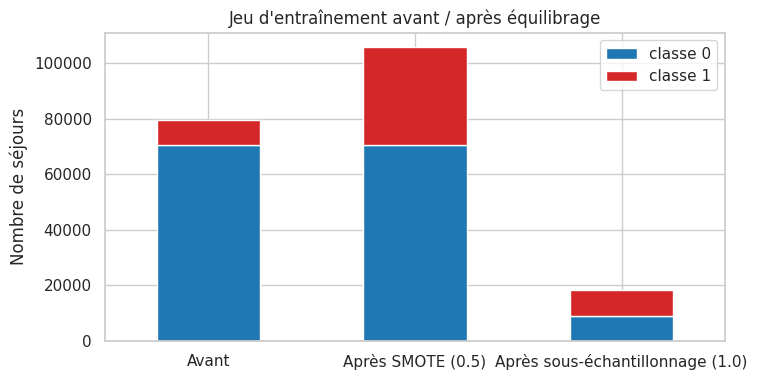

Test (non modifié) : classe 1 = 11.35 %


In [ ]:
# Démonstration sur le jeu d'entraînement (le test n'est jamais modifié)
Xtr_dense = X_train_transformed.toarray()
Xte_dense = X_test_transformed.toarray()

_, y_smote = smote(Xtr_dense, y_train, ratio=0.5)
_, y_sous = sous_echantillonnage(Xtr_dense, y_train, ratio=1.0)

equilibrage = pd.DataFrame({
    "Avant": pd.Series(y_train.values).value_counts(),
    "Après SMOTE (0.5)": pd.Series(y_smote).value_counts(),
    "Après sous-échantillonnage (1.0)": pd.Series(y_sous).value_counts(),
}).rename(index={0: "classe 0", 1: "classe 1"})
display(equilibrage)

equilibrage.T.plot(kind="bar", stacked=True, figsize=(8, 4), color=["tab:blue", "tab:red"])
plt.title("Jeu d'entraînement avant / après équilibrage")
plt.ylabel("Nombre de séjours"); plt.xticks(rotation=0)
plt.show()
print("Test (non modifié) : classe 1 =", round(y_test.mean() * 100, 2), "%")

**Interprétation :**

| | Classe 0 | Classe 1 | Rapport |
|---|---|---|---|
| Avant | 70 497 | 9 070 | ≈ 7,8 pour 1 |
| Après SMOTE (ratio 0,5) | 70 497 | 35 248 (26 178 synthétiques) | 2 pour 1 |
| Après sous-échantillonnage (ratio 1) | 9 070 | 9 070 | 1 pour 1 (61 427 séjours retirés) |

Le **test n'est pas modifié** (11,35 % de réadmissions). Ce tableau est une démonstration : l'équilibrage réel est appliqué pendant l'entraînement (4.2), dans chaque pli de la validation croisée, et le ratio (0,5 ou 1) y est choisi automatiquement.

### 3.13 Données de segmentation : filtrage des variables numériques

La segmentation (K-Means) repose sur des **distances**, et la PCA sur des **variances et corrélations** : ces calculs n'ont pas de sens sur des colonnes binaires issues du One-Hot. Nous **filtrons donc les 9 variables quantitatives** (les 8 numériques + `age` ordinal). Les variables catégorielles ne construisent pas les clusters : elles servent ensuite à les **décrire**. La cible n'est pas utilisée.

Les trois variables de visites antérieures sont transformées par `log1p` (log(1 + x)) pour réduire l'effet des valeurs extrêmes, puis toutes les variables sont standardisées.

In [ ]:
pca_vars = vars_numeriques + ["age"]
log_cols = ["number_outpatient", "number_emergency", "number_inpatient"]

X_num = df_clean[pca_vars].copy()
X_num["age"] = X_num["age"].map(age_mapping)
asym_avant = X_num[log_cols].skew()
X_num[log_cols] = np.log1p(X_num[log_cols])          # réduit l'asymétrie
print("Asymétrie avant / après log1p :")
print(pd.DataFrame({"avant": asym_avant, "après": X_num[log_cols].skew()}).round(2))

readmission_seg = df_clean["readmitted_30"].values   # gardée à part, pour l'analyse après clustering

scaler_pca = StandardScaler()
X_num_scaled = scaler_pca.fit_transform(X_num)
print("\nDonnées de segmentation :", X_num_scaled.shape)

Asymétrie avant / après log1p :
                   avant  après
number_outpatient   8.84   2.74
number_emergency   22.85   3.67
number_inpatient    3.63   1.46

Données de segmentation : (99340, 9)


**Interprétation :** les 9 variables quantitatives sont filtrées pour la segmentation. `log1p` réduit fortement l'asymétrie des visites antérieures (urgences : 22,9 → 3,7 ; consultations : 8,8 → 2,7 ; hospitalisations : 3,6 → 1,5), ce qui évite que quelques patients extrêmes dominent les distances.

### 3.14 Analyse en composantes principales (PCA)

Le nombre de composantes est choisi avec le **critère de Kaiser** (valeur propre > 1) et un seuil de **80 % de variance expliquée**.

,valeur propre,variance (%),cumulée (%)
PC1,2.058,22.9,22.9
PC2,1.459,16.2,39.1
PC3,1.159,12.9,52.0
PC4,0.990,11.0,62.9
PC5,0.837,9.3,72.3
PC6,0.729,8.1,80.4
PC7,0.675,7.5,87.9
PC8,0.624,6.9,94.8
PC9,0.468,5.2,100.0


Critère de Kaiser : 3 composantes | seuil de 80 % : 6 composantes


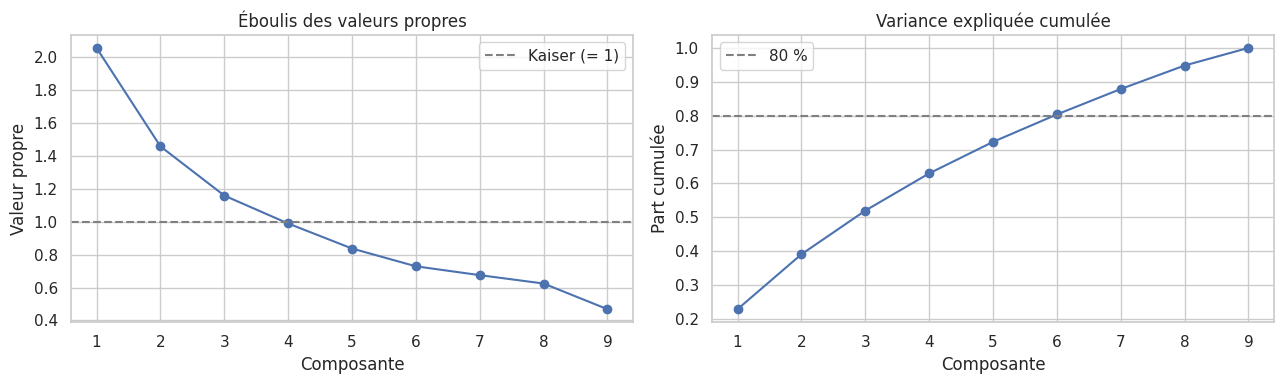

In [ ]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_num_scaled)
valeurs_propres = pca_full.explained_variance_
variance_cumulee = np.cumsum(pca_full.explained_variance_ratio_)

display(pd.DataFrame({
    "valeur propre": valeurs_propres.round(3),
    "variance (%)": (pca_full.explained_variance_ratio_ * 100).round(1),
    "cumulée (%)": (variance_cumulee * 100).round(1),
}, index=[f"PC{i+1}" for i in range(len(valeurs_propres))]))

n_kaiser = int((valeurs_propres > 1).sum())
n_80 = int(np.argmax(variance_cumulee >= 0.80) + 1)
print("Critère de Kaiser :", n_kaiser, "composantes | seuil de 80 % :", n_80, "composantes")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rang = range(1, len(valeurs_propres) + 1)
ax[0].plot(rang, valeurs_propres, marker="o"); ax[0].axhline(1, ls="--", c="grey", label="Kaiser (= 1)")
ax[0].set(title="Éboulis des valeurs propres", xlabel="Composante", ylabel="Valeur propre"); ax[0].legend()
ax[1].plot(rang, variance_cumulee, marker="o"); ax[1].axhline(0.80, ls="--", c="grey", label="80 %")
ax[1].set(title="Variance expliquée cumulée", xlabel="Composante", ylabel="Part cumulée"); ax[1].legend()
plt.tight_layout(); plt.show()

(99340, 9) -> (99340, 6) | variance conservée : 80.4 %


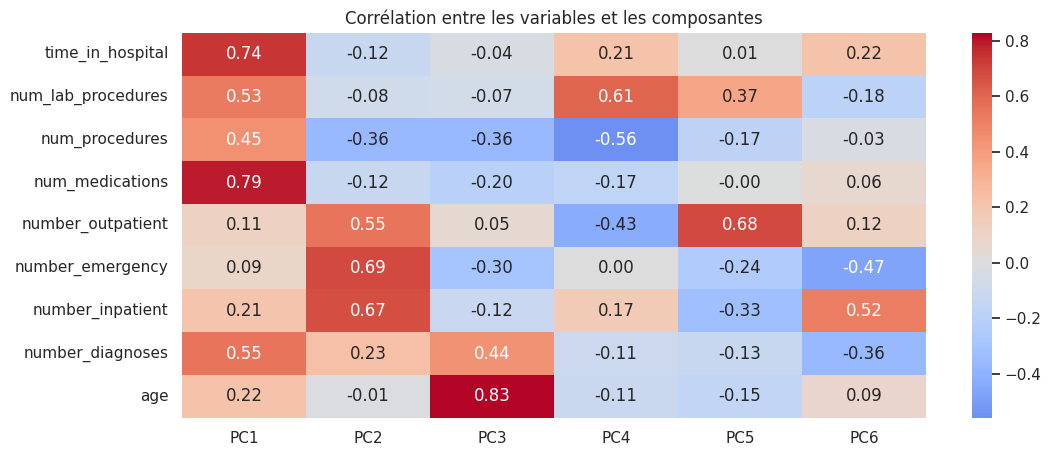

In [ ]:
# PCA finale : 80 % de variance
n_components = n_80
pca = PCA(n_components=n_components, random_state=SEED)
X_segmentation_pca = pca.fit_transform(X_num_scaled)
print(X_num_scaled.shape, "->", X_segmentation_pca.shape,
      "| variance conservée :", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

# Corrélations variables / composantes (loadings)
noms_pc = [f"PC{i+1}" for i in range(n_components)]
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=pca_vars, columns=noms_pc)
plt.figure(figsize=(1.5 * n_components + 3, 5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation entre les variables et les composantes")
plt.show()

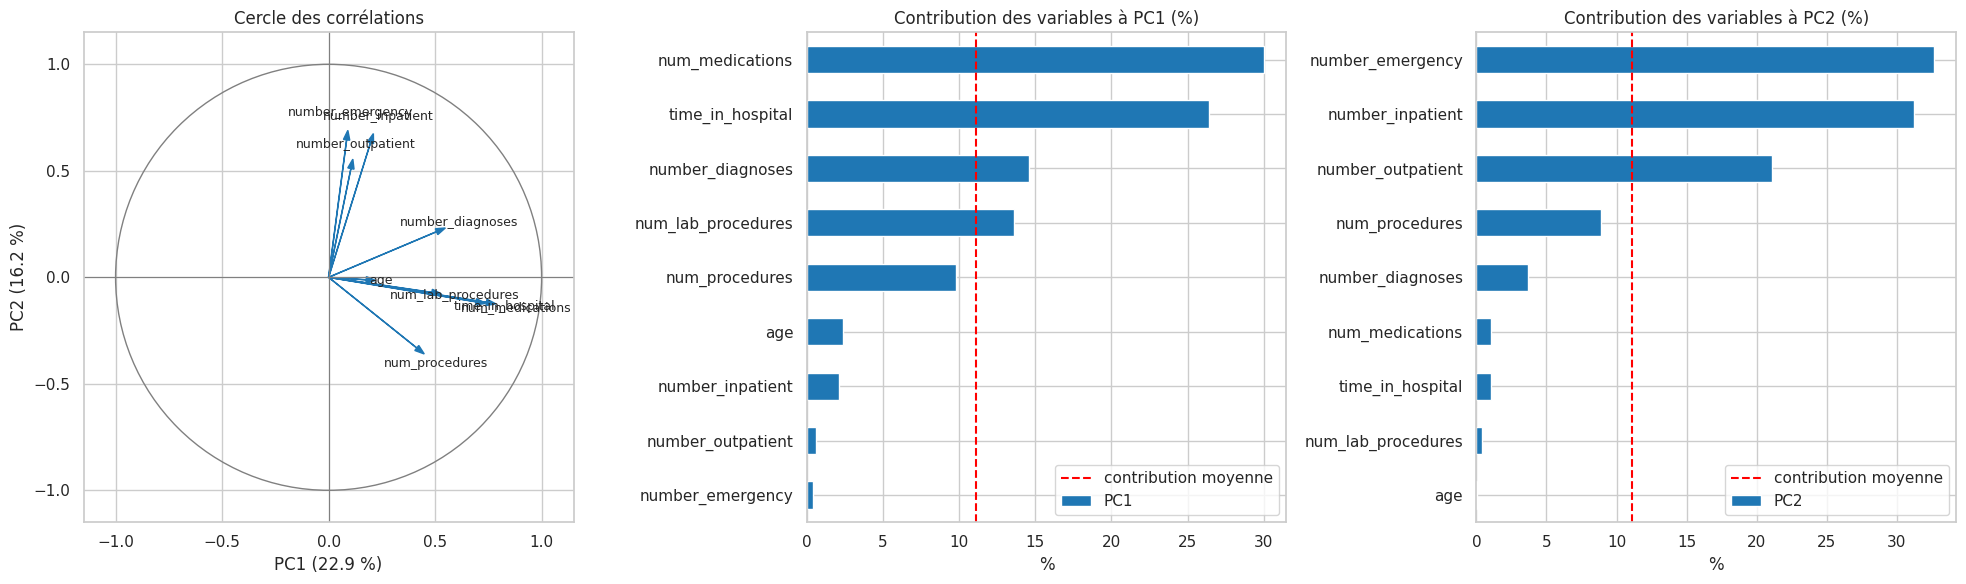

,PC1,PC2,PC3,PC4,PC5,PC6
time_in_hospital,26.4,1.0,0.1,4.5,0.0,6.4
num_lab_procedures,13.6,0.4,0.4,37.1,16.0,4.7
num_procedures,9.8,8.9,10.9,31.5,3.6,0.1
num_medications,30.0,1.1,3.5,2.8,0.0,0.5
number_outpatient,0.6,21.1,0.3,18.9,56.0,2.1
number_emergency,0.4,32.6,7.5,0.0,6.9,30.5
number_inpatient,2.1,31.2,1.2,2.8,12.7,37.0
number_diagnoses,14.6,3.7,16.9,1.1,2.0,17.7
age,2.4,0.0,59.3,1.2,2.7,1.0


In [ ]:
# Cercle des corrélations (PC1 x PC2) et contributions des variables
fig, ax = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax[0].add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for var in pca_vars:
    x, y_ = loadings.loc[var, "PC1"], loadings.loc[var, "PC2"]
    ax[0].arrow(0, 0, x, y_, head_width=0.03, length_includes_head=True, color="tab:blue")
    ax[0].text(x * 1.12, y_ * 1.12, var, ha="center", va="center", fontsize=9)
ax[0].axhline(0, c="grey", lw=0.8); ax[0].axvline(0, c="grey", lw=0.8)
ax[0].set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal", title="Cercle des corrélations",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)")

contributions = pd.DataFrame(pca.components_.T ** 2 * 100, index=pca_vars, columns=noms_pc)
for a, pc in zip(ax[1:], ["PC1", "PC2"]):
    contributions[pc].sort_values().plot(kind="barh", ax=a, color="tab:blue")
    a.axvline(100 / len(pca_vars), ls="--", c="red", label="contribution moyenne")
    a.set(title=f"Contribution des variables à {pc} (%)", xlabel="%"); a.legend()
plt.tight_layout(); plt.show()
display(contributions.round(1))

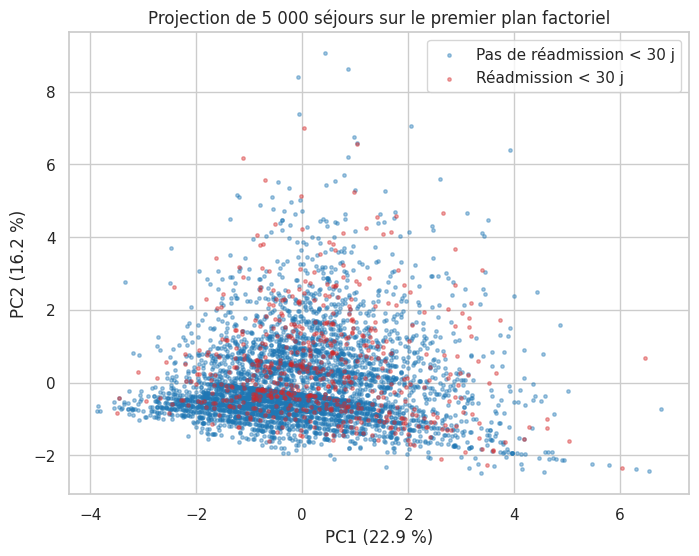

In [ ]:
# Projection de 5 000 séjours sur le premier plan (la cible sert seulement à colorer)
idx = np.random.RandomState(SEED).choice(len(X_segmentation_pca), 5000, replace=False)
plt.figure(figsize=(8, 6))
for classe, couleur, nom in [(0, "tab:blue", "Pas de réadmission < 30 j"), (1, "tab:red", "Réadmission < 30 j")]:
    m = readmission_seg[idx] == classe
    plt.scatter(X_segmentation_pca[idx][m, 0], X_segmentation_pca[idx][m, 1], s=6, alpha=0.4, c=couleur, label=nom)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)")
plt.title("Projection de 5 000 séjours sur le premier plan factoriel")
plt.legend(); plt.show()

**Interprétation :**
- **Choix du nombre de composantes :** Kaiser retient 3 composantes (52 % de la variance seulement) ; nous gardons **6 composantes (80,4 %)**. La variance est répartie de façon assez uniforme (PC1 = 22,9 %), car les variables sont peu corrélées : la PCA réduit modestement la dimension (9 → 6).
- **PC1 (22,9 %) — lourdeur du séjour actuel :** `num_medications` (0,79), `time_in_hospital` (0,74), `number_diagnoses` (0,55), `num_lab_procedures` (0,53), `num_procedures` (0,45).
- **PC2 (16,2 %) — recours antérieur aux soins :** `number_emergency` (0,69), `number_inpatient` (0,67), `number_outpatient` (0,55).
- **PC3 (12,9 %) — âge et comorbidités :** `age` (0,83), `number_diagnoses` (0,44).
- **PC4 (11 %)** oppose les examens biologiques (0,61) aux actes techniques (−0,56).
- **Projection :** les séjours réadmis sont mélangés aux autres, avec une présence un peu plus forte quand PC2 est élevé (patients souvent hospitalisés). Il n'y a pas de groupe nettement séparé.

### 3.15 Export et synthèse de la Data Preparation

In [ ]:
df_clean.to_csv("diabetic_data_clean.csv", index=False)

synthese = pd.DataFrame({
    "Avant": [f"{df.shape[0]:,}".replace(",", " "), df["patient_nbr"].nunique(), df.shape[1],
              round((df["readmitted"] == "<30").mean() * 100, 2), "non (ancienne version)",
              "ancienne version : 226 colonnes One-Hot -> 60 composantes"],
    "Après": [f"{df_clean.shape[0]:,}".replace(",", " "), df_clean["patient_nbr"].nunique(), df_clean.shape[1],
              round(df_clean["readmitted_30"].mean() * 100, 2), "oui (train uniquement)",
              f"{len(pca_vars)} variables numériques -> {n_components} composantes"],
}, index=["Séjours", "Patients", "Colonnes", "Réadmission < 30 j (%)", "Équilibrage des classes", "Entrée de la PCA"])
display(synthese)
print("Fichier exporté : diabetic_data_clean.csv")

,Avant,Après
Séjours,101 766,99 340
Patients,71518,69987
Colonnes,50,33
Réadmission < 30 j (%),11.16,11.39
Équilibrage des classes,non (ancienne version),oui (train uniquement)
Entrée de la PCA,ancienne version : 226 colonnes One-Hot -> 60 ...,9 variables numériques -> 6 composantes


Fichier exporté : diabetic_data_clean.csv


**Conclusion de la Data Preparation :** les données sont **propres** (0 manquant, 0 doublon, variables inutiles et séjours non réadmissibles supprimés, diagnostics et spécialités regroupés) et **sans fuite d'information** (séparation par patient, `readmitted` supprimée, encodage ajusté sur le train). Le **déséquilibre** est traité sur le train uniquement. La segmentation repose sur une **PCA des 9 variables numériques** (6 composantes, 80,4 %). Les données sont prêtes pour le Modeling.

## 4. Modeling

### 4.1 Clustering K-Means (BO2)

K-Means regroupe les séjours proches dans l'espace des composantes. Nous testons `k` de 2 à 8 et comparons deux représentations : **avec PCA** (6 composantes) et **sans PCA** (9 variables standardisées). Les indicateurs sont calculés sur un échantillon de 10 000 séjours (la silhouette est coûteuse), K-Means étant ajusté sur tous les séjours.

* **Silhouette** (de −1 à 1, plus haut = mieux) : cohésion et séparation des groupes ;
* **Davies-Bouldin** (plus bas = mieux) : ressemblance entre clusters voisins ;
* **Calinski-Harabasz** (plus haut = mieux) : rapport dispersion entre / dans les clusters ;
* **Inertie** : compacité (méthode du coude).

,representation,k,inertie,silhouette,davies_bouldin,calinski_harabasz
0,Avec PCA (6 composantes),2,590031.507,0.193,1.984,2133.670
1,Avec PCA (6 composantes),3,508285.980,0.203,1.678,2057.178
2,Avec PCA (6 composantes),4,449267.621,0.170,1.620,1974.720
3,Avec PCA (6 composantes),5,398837.210,0.188,1.474,2005.601
4,Avec PCA (6 composantes),6,365513.868,0.177,1.456,1924.615
5,Avec PCA (6 composantes),7,336656.059,0.189,1.361,1906.401
6,Avec PCA (6 composantes),8,313792.099,0.185,1.309,1861.584
7,Sans PCA (9 variables),2,765544.114,0.159,2.302,1651.057
8,Sans PCA (9 variables),3,682912.392,0.164,1.923,1545.472
9,Sans PCA (9 variables),4,620246.353,0.136,1.944,1471.949


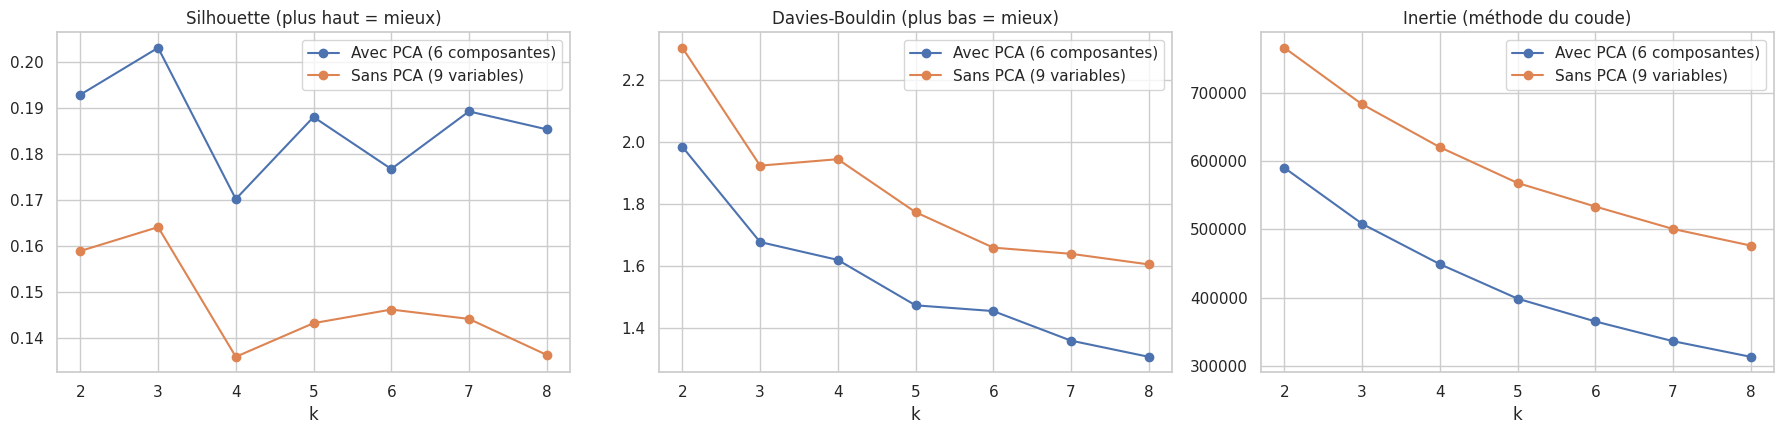

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

echantillon = np.random.RandomState(SEED).choice(len(X_segmentation_pca), 10000, replace=False)


def evaluer_k(X, nom, k_values=range(2, 9)):
    lignes = []
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
        labels = km.fit_predict(X)
        Xs, ls = X[echantillon], labels[echantillon]
        lignes.append({"representation": nom, "k": k, "inertie": km.inertia_,
                       "silhouette": silhouette_score(Xs, ls),
                       "davies_bouldin": davies_bouldin_score(Xs, ls),
                       "calinski_harabasz": calinski_harabasz_score(Xs, ls)})
    return pd.DataFrame(lignes)


res_pca = evaluer_k(X_segmentation_pca, "Avec PCA (6 composantes)")
res_sans = evaluer_k(X_num_scaled, "Sans PCA (9 variables)")
resultats_k = pd.concat([res_pca, res_sans], ignore_index=True)
display(resultats_k.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for nom, g in resultats_k.groupby("representation"):
    axes[0].plot(g["k"], g["silhouette"], marker="o", label=nom)
    axes[1].plot(g["k"], g["davies_bouldin"], marker="o", label=nom)
    axes[2].plot(g["k"], g["inertie"], marker="o", label=nom)
for a, t in zip(axes, ["Silhouette (plus haut = mieux)", "Davies-Bouldin (plus bas = mieux)", "Inertie (méthode du coude)"]):
    a.set(title=t, xlabel="k"); a.legend()
plt.tight_layout(); plt.show()

**Interprétation :**
- **Avec PCA, la silhouette est meilleure pour tous les `k`** (0,203 contre 0,164 pour k = 3), ainsi que Davies-Bouldin (1,68 contre 1,92) et Calinski-Harabasz : la PCA est conservée.
- La silhouette est **maximale pour k = 3 (0,203)**, dans la fourchette du BO2. Davies-Bouldin s'améliore quand `k` augmente et l'inertie diminue sans coude net : ces indicateurs ne désignent pas un autre `k` clairement.
- Une silhouette autour de 0,2 (< 0,25) indique une **structure faible** : les groupes se chevauchent en partie.

**Règle de décision :** parmi les valeurs de `k` compatibles avec le BO2 (**3 à 6**), on retient celle qui maximise la silhouette avec PCA.

In [ ]:
candidats = res_pca[res_pca["k"].between(3, 6)]
K_FINAL = int(candidats.loc[candidats["silhouette"].idxmax(), "k"])
print("k retenu :", K_FINAL)

kmeans_final = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=20)
cluster_labels = kmeans_final.fit_predict(X_segmentation_pca)

taille = pd.Series(cluster_labels).value_counts().sort_index()
display(pd.DataFrame({"séjours": taille, "%": (taille / len(cluster_labels) * 100).round(1)}).rename_axis("cluster"))

k retenu : 3


,séjours,%
cluster,,
0,29812,30.0
1,55166,55.5
2,14362,14.5


**Interprétation :** **k = 3** est retenu. Les trois clusters regroupent **30,0 %**, **55,5 %** et **14,5 %** des séjours : tous sont assez grands pour être actionnables.

### 4.2 Classification (BO1)

* **Données :** `X_train_transformed` / `X_test_transformed` (séparation par patient, préprocesseur ajusté sur le train).
* **Modèles :** un *Dummy* (référence du hasard), un **arbre de décision** et un **KNN**.
* **Équilibrage :** SMOTE pour l'arbre (il garde toutes les données réelles), sous-échantillonnage pour le KNN (moins de lignes, donc des distances beaucoup plus rapides à calculer). Il est appliqué dans `ModeleReequilibre`, donc **seulement sur les plis d'entraînement**.
* **Réglage :** `GridSearchCV` sur le train, validation croisée **groupée par patient** (`GroupKFold`), score = **PR-AUC** (adaptée au déséquilibre). Le ratio d'équilibrage fait partie des paramètres testés.
* **Comparaison :** les mêmes modèles **sans équilibrage** servent à mesurer l'apport de l'équilibrage.

In [ ]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold

cv = GroupKFold(n_splits=3)   # aucun patient à la fois en entraînement et en validation

# --- Arbre de décision + SMOTE
t0 = time.time()
gs_tree = GridSearchCV(
    ModeleReequilibre(DecisionTreeClassifier(random_state=SEED), methode="smote"),
    param_grid={"ratio": [0.5, 1.0],
                "estimator__max_depth": [4, 6, 8, 10],
                "estimator__min_samples_leaf": [50, 100, 200]},
    scoring="average_precision", cv=cv, n_jobs=-1)
gs_tree.fit(Xtr_dense, y_train, groups=groups_train)
print(f"Arbre + SMOTE        : {gs_tree.best_params_} | PR-AUC validation = {gs_tree.best_score_:.3f} ({time.time()-t0:.0f} s)")

# --- KNN + sous-échantillonnage
t0 = time.time()
gs_knn = GridSearchCV(
    ModeleReequilibre(KNeighborsClassifier(), methode="sous"),
    param_grid={"ratio": [0.5, 1.0], "estimator__n_neighbors": [25, 50, 100, 200]},
    scoring="average_precision", cv=cv, n_jobs=-1)
gs_knn.fit(Xtr_dense, y_train, groups=groups_train)
print(f"KNN + sous-éch.      : {gs_knn.best_params_} | PR-AUC validation = {gs_knn.best_score_:.3f} ({time.time()-t0:.0f} s)")

Arbre + SMOTE        : {'estimator__max_depth': 8, 'estimator__min_samples_leaf': 50, 'ratio': 0.5} | PR-AUC validation = 0.189 (154 s)
KNN + sous-éch.      : {'estimator__n_neighbors': 200, 'ratio': 0.5} | PR-AUC validation = 0.195 (162 s)


In [ ]:
# Modèles de référence SANS équilibrage (mêmes hyperparamètres) pour mesurer l'effet de l'équilibrage
t0 = time.time()
arbre_sans = ModeleReequilibre(DecisionTreeClassifier(random_state=SEED,
                                                      max_depth=gs_tree.best_params_["estimator__max_depth"],
                                                      min_samples_leaf=gs_tree.best_params_["estimator__min_samples_leaf"]),
                               methode="aucun").fit(Xtr_dense, y_train)
knn_sans = ModeleReequilibre(KNeighborsClassifier(n_neighbors=gs_knn.best_params_["estimator__n_neighbors"]),
                             methode="aucun").fit(Xtr_dense, y_train)

models = {
    "Dummy (hasard)": DummyClassifier(strategy="prior").fit(Xtr_dense, y_train),
    "Arbre sans équilibrage": arbre_sans,
    "Arbre + SMOTE": gs_tree.best_estimator_,
    "KNN sans équilibrage": knn_sans,
    "KNN + sous-échantillonnage": gs_knn.best_estimator_,
}
scores_test = {nom: m.predict_proba(Xte_dense)[:, 1] for nom, m in models.items()}
cv_pr_auc = {"Arbre + SMOTE": gs_tree.best_score_, "KNN + sous-échantillonnage": gs_knn.best_score_}
print(f"Modèles entraînés et scores calculés sur le test ({time.time()-t0:.0f} s).")

Modèles entraînés et scores calculés sur le test (40 s).


**Interprétation :**
- **Arbre + SMOTE :** meilleurs paramètres profondeur 10, au moins 50 séjours par feuille, ratio 0,5 ; **PR-AUC de validation = 0,191**.
- **KNN + sous-échantillonnage :** 200 voisins, ratio 0,5 ; **PR-AUC = 0,196**.
- Les deux font environ **1,7 fois mieux que le hasard** (0,114). Dans les deux cas, un équilibrage **partiel** (ratio 0,5) donne de meilleurs résultats qu'un équilibrage complet (1 pour 1).
- Les mêmes modèles sans équilibrage sont gardés pour comparaison.

## 5. Evaluation

La phase Evaluation vérifie la qualité technique des modèles **et** leur réponse aux objectifs métier (BO1, BO2).

### 5.1 Évaluation du clustering (BO2)

#### 5.1.1 Qualité et stabilité des clusters

In [ ]:
from sklearn.metrics import silhouette_samples, adjusted_rand_score

display(resultats_k[resultats_k["k"] == K_FINAL].round(3))

sil = silhouette_samples(X_segmentation_pca[echantillon], cluster_labels[echantillon])
print("Silhouette moyenne par cluster :")
print(pd.Series(sil).groupby(cluster_labels[echantillon]).mean().round(3))

# Stabilité : on relance K-Means avec d'autres graines et on compare (Adjusted Rand Index, 1 = identique)
ari = [adjusted_rand_score(cluster_labels,
                           KMeans(n_clusters=K_FINAL, random_state=s, n_init=5).fit_predict(X_segmentation_pca))
       for s in [1, 7, 21, 99, 123]]
print("\nARI par graine :", np.round(ari, 3), "| moyenne :", round(float(np.mean(ari)), 3))

,representation,k,inertie,silhouette,davies_bouldin,calinski_harabasz
1,Avec PCA (6 composantes),3,508285.980,0.203,1.678,2057.178
8,Sans PCA (9 variables),3,682912.392,0.164,1.923,1545.472


Silhouette moyenne par cluster :
0    0.182
1    0.264
2    0.025
dtype: float64

ARI par graine : [0.998 0.994 0.994 0.997 0.994] | moyenne : 0.996


**Interprétation :**
- **Silhouette = 0,203** (Davies-Bouldin = 1,68) : séparation faible mais réelle.
- Par cluster, la silhouette vaut 0,18 / 0,26 / 0,03 : le **cluster 1 est le plus net**, le **cluster 2 le plus mélangé** avec les autres.
- **ARI moyen = 0,996** : les clusters sont **très stables**, K-Means retrouve presque exactement les mêmes groupes quelle que soit la graine.

#### 5.1.2 Profil des clusters

La cible `readmitted_30` n'a pas servi à construire les clusters : elle sert seulement à les décrire.

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age_num,séjours,réadmission_%
cluster,,,,,,,,,,,
0,7.16,55.08,2.30,22.90,0.11,0.06,0.60,8.32,6.37,29812,12.68
1,2.98,36.57,0.92,12.13,0.08,0.04,0.34,6.70,5.93,55166,9.14
2,3.99,42.00,0.91,16.39,2.03,1.09,1.84,8.18,6.00,14362,17.34


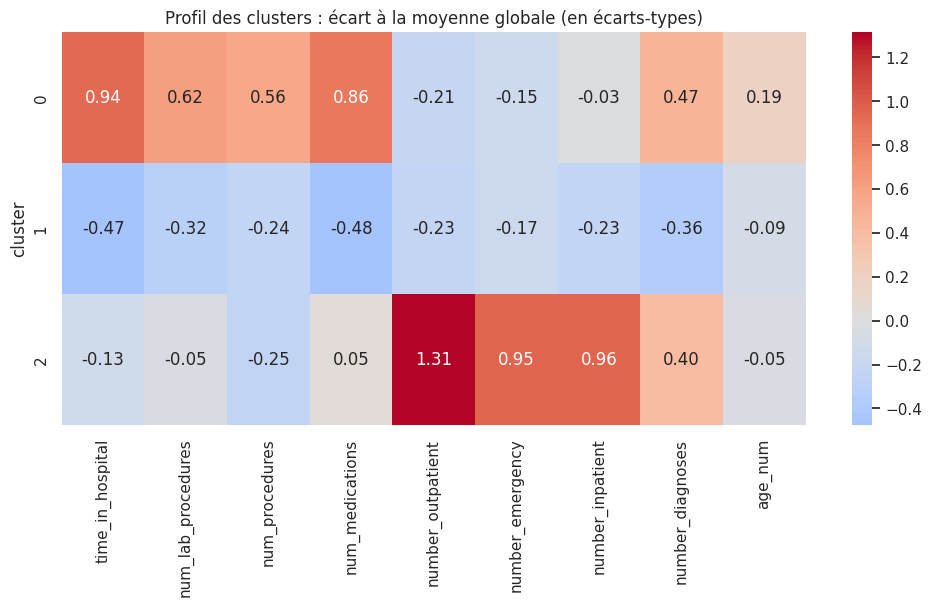

In [ ]:
profil = df_clean.copy()
profil["cluster"] = cluster_labels
profil["age_num"] = profil["age"].map(age_mapping)
vars_profil = vars_numeriques + ["age_num"]

resume = profil.groupby("cluster")[vars_profil].mean()
resume["séjours"] = profil.groupby("cluster").size()
resume["réadmission_%"] = profil.groupby("cluster")["readmitted_30"].mean() * 100
display(resume.round(2))

# Écart de chaque cluster à la moyenne globale, en écarts-types
z = (resume[vars_profil] - profil[vars_profil].mean()) / profil[vars_profil].std()
plt.figure(figsize=(12, 1.2 * K_FINAL + 1.5))
sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Profil des clusters : écart à la moyenne globale (en écarts-types)")
plt.show()

In [ ]:
# Variables catégorielles : répartition (%) par cluster
for col in ["diag_1_group", "admission_type_id", "discharge_disposition_id"]:
    tab = pd.crosstab(profil["cluster"], profil[col], normalize="index") * 100
    tab = tab[tab.mean().sort_values(ascending=False).index[:6]]      # 6 modalités les plus fréquentes
    print(f"--- {col} (%) ---")
    display(tab.round(1))
print("Codes : admission_type_id 1 = urgence, 2 = urgent, 3 = programmé ; "
      "discharge_disposition_id 1 = domicile, 3 = établissement de soins (SNF), 6 = domicile avec soins")

--- diag_1_group (%) ---


diag_1_group,Circulatory,Other,Respiratory,Digestive,Diabetes,Injury
cluster,,,,,,
0,34.3,15.4,12.7,9.2,6.7,8.3
1,28.7,18.7,14.4,9.4,9.2,6.2
2,25.3,20.1,15.2,9.9,11.2,6.6


--- admission_type_id (%) ---


admission_type_id,1,2,3,5,6,8
cluster,,,,,,
0,52.6,18.0,20.5,2.2,6.4,0.2
1,51.8,18.7,19.3,4.6,5.1,0.4
2,56.3,17.1,13.4,9.9,3.1,0.2


--- discharge_disposition_id (%) ---


discharge_disposition_id,1,3,6,18,2,22
cluster,,,,,,
0,47.0,20.9,17.6,4.6,2.0,3.2
1,69.4,9.6,9.0,4.0,2.1,1.5
2,55.3,16.9,18.6,0.7,2.7,1.4


Codes : admission_type_id 1 = urgence, 2 = urgent, 3 = programmé ; discharge_disposition_id 1 = domicile, 3 = établissement de soins (SNF), 6 = domicile avec soins


**Interprétation :**

| Cluster | Part | Profil (comparé à la moyenne) | Réadmission < 30 j |
|---|---|---|---|
| **0** | 30 % | **Séjours longs et lourds** : 7,2 jours, 23 médicaments, 55 examens, 2,3 actes, 8,3 diagnostics ; plus souvent transférés en établissement (21 %) ou à domicile avec soins (18 %) | 12,7 % |
| **1** | 55,5 % | **Séjours courts et légers** : 3,0 jours, 12 médicaments, 6,7 diagnostics, peu de visites antérieures ; 69 % rentrent directement à domicile | **9,1 %** (le plus bas) |
| **2** | 14,5 % | **Usagers fréquents de l'hôpital** : 2,0 consultations, 1,1 passage aux urgences et 1,8 hospitalisation l'année précédente (contre 0,1 à 0,6 ailleurs) ; plus d'admissions en urgence | **17,3 %** (le plus haut) |

Les diagnostics principaux sont proches entre clusters (circulatoire en tête partout) : les segments se distinguent surtout par la **lourdeur du séjour** et l'**historique de soins**.

#### 5.1.3 Les segments ont-ils des risques de réadmission différents ?

Test du **χ²** d'indépendance entre cluster et réadmission. Avec près de 100 000 séjours, la p-value est presque toujours significative : on mesure donc aussi la **force** de l'association avec le **V de Cramér** (< 0,1 = faible).

In [ ]:
from itertools import combinations
from scipy.stats import chi2_contingency

table = pd.crosstab(profil["cluster"], profil["readmitted_30"])
chi2, p, ddl, _ = chi2_contingency(table)
v_cramer = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"Chi2 = {chi2:.1f} | ddl = {ddl} | p-value = {p:.3g} | V de Cramér = {v_cramer:.3f}")

seuil_bonf = 0.05 / len(list(combinations(range(K_FINAL), 2)))
print(f"\nComparaisons deux à deux (seuil de Bonferroni : p < {seuil_bonf:.4f}) :")
for a, b in combinations(range(K_FINAL), 2):
    sous_table = pd.crosstab(profil.loc[profil["cluster"].isin([a, b]), "cluster"],
                             profil.loc[profil["cluster"].isin([a, b]), "readmitted_30"])
    c2, pp, _, _ = chi2_contingency(sous_table)
    print(f"  cluster {a} vs {b} : chi2 = {c2:.1f} | p = {pp:.3g} | {'différents' if pp < seuil_bonf else 'non distinguables'}")

Chi2 = 830.0 | ddl = 2 | p-value = 5.76e-181 | V de Cramér = 0.091

Comparaisons deux à deux (seuil de Bonferroni : p < 0.0167) :
  cluster 0 vs 1 : chi2 = 260.0 | p = 1.74e-58 | différents
  cluster 0 vs 2 : chi2 = 172.8 | p = 1.83e-39 | différents
  cluster 1 vs 2 : chi2 = 792.8 | p = 2.03e-174 | différents


**Interprétation :** χ² = 830 (p ≈ 10⁻¹⁸¹) : le taux de réadmission **dépend du cluster**, et **les trois clusters sont différents deux à deux** (tests de Bonferroni significatifs). Le V de Cramér (**0,091**) indique cependant une association **faible** : le cluster explique une petite part du risque, ce qui est normal pour une segmentation construite sans la cible.

#### 5.1.4 Interprétation clinique des segments et verdict BO2

| Cluster | Nom proposé | Parcours de soins suggéré |
|---|---|---|
| **1** (55,5 %, réadmission 9,1 %) | **Séjours courts, profil léger** | Sortie standard, information du patient, suivi habituel |
| **0** (30 %, réadmission 12,7 %) | **Séjours longs, prise en charge lourde** | Revue des médicaments avant la sortie, coordination avec l'établissement d'aval, rendez-vous précoce |
| **2** (14,5 %, réadmission 17,3 %) | **Usagers fréquents de l'hôpital** | Gestion de cas, appel de suivi après la sortie, coordination avec le médecin traitant |

**Verdict BO2**

| Critère de succès | Résultat | Atteint ? |
|---|---|---|
| 3 à 6 segments | k = 3 | ✅ |
| Assez grands pour être actionnables | 30 % / 55,5 % / 14,5 % | ✅ |
| Compréhensibles | Trois profils lisibles (léger / lourd / usager fréquent) | ✅ (à valider avec des cliniciens) |
| Différents par leur risque | 9,1 % / 12,7 % / 17,3 %, différences significatives ; association faible (V = 0,09) | ✅ avec réserve |
| Qualité technique | Silhouette 0,20 (faible) ; stabilité très forte (ARI 0,996) | ⚠️ partiel |

**Limites :** les segments décrivent des tendances plutôt que des groupes tranchés ; ils portent sur des **séjours** (un patient peut changer de segment) ; seules les variables numériques construisent les clusters.

### 5.2 Évaluation de la classification (BO1)

Le jeu de test sert uniquement à **mesurer** les performances : le modèle et le seuil sont choisis sur le train.

#### 5.2.1 Qualité du classement et effet de l'équilibrage

* **ROC-AUC** et **PR-AUC** mesurent la qualité du classement des patients, sans seuil. La PR-AUC d'un modèle aléatoire vaut la prévalence (≈ 11 %).
* **Top 20 %** : part des réadmissions capturées si l'on suit les 20 % de patients les plus à risque (hasard = 20 %).
* **Recall au seuil 0,5** : part des réadmissions détectées avec le seuil par défaut. C'est là que l'équilibrage a le plus d'effet.

Prévalence du test (PR-AUC du hasard) : 0.113


,ROC-AUC,PR-AUC,Top 20 %,"Recall (seuil 0,5)","Précision (seuil 0,5)"
Modèle,,,,,
Dummy (hasard),0.500,0.113,0.213,0.000,0.000
Arbre sans équilibrage,0.654,0.211,0.383,0.031,0.504
Arbre + SMOTE,0.638,0.192,0.352,0.104,0.319
KNN sans équilibrage,0.644,0.212,0.360,0.002,0.800
KNN + sous-échantillonnage,0.650,0.213,0.367,0.094,0.325


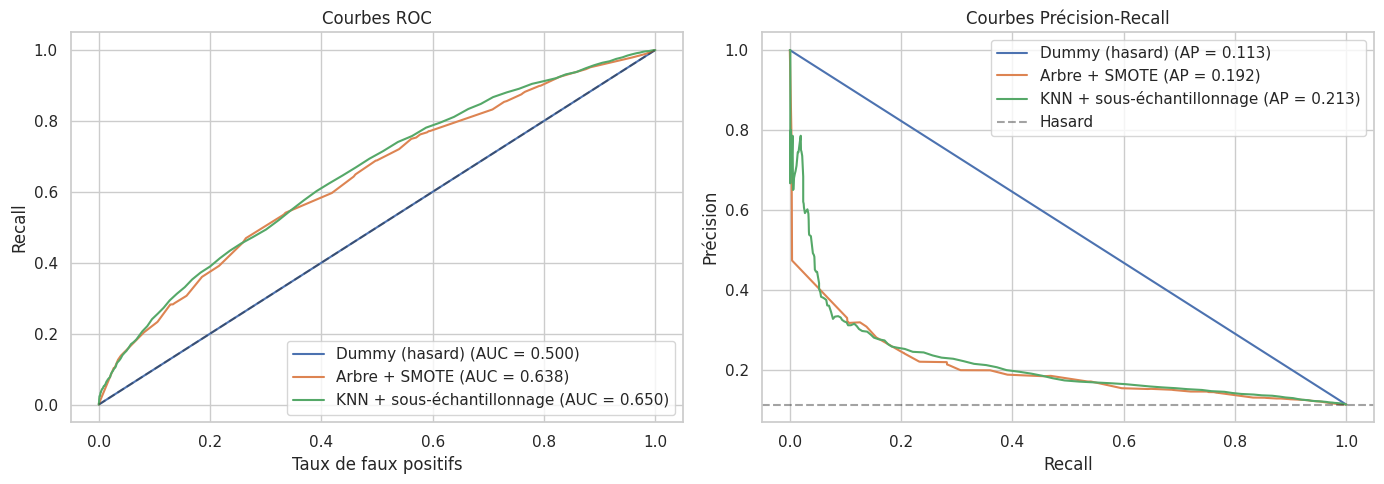

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, fbeta_score, accuracy_score, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)


def recall_top(y_true, score, frac=0.20):
    """Part des réadmissions parmi les `frac` séjours de score le plus élevé."""
    n = int(len(y_true) * frac)
    top = np.argsort(-score, kind="stable")[:n]
    return np.asarray(y_true)[top].sum() / np.asarray(y_true).sum()


lignes = []
for nom, s in scores_test.items():
    lignes.append({"Modèle": nom,
                   "ROC-AUC": roc_auc_score(y_test, s),
                   "PR-AUC": average_precision_score(y_test, s),
                   "Top 20 %": recall_top(y_test, s),
                   "Recall (seuil 0,5)": recall_score(y_test, (s >= 0.5).astype(int)),
                   "Précision (seuil 0,5)": precision_score(y_test, (s >= 0.5).astype(int), zero_division=0)})
res_test = pd.DataFrame(lignes).set_index("Modèle")
print("Prévalence du test (PR-AUC du hasard) :", round(y_test.mean(), 3))
display(res_test.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nom in ["Dummy (hasard)", "Arbre + SMOTE", "KNN + sous-échantillonnage"]:
    s = scores_test[nom]
    fpr, tpr, _ = roc_curve(y_test, s)
    ax[0].plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, s):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax[1].plot(rc, pr, label=f"{nom} (AP = {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set(title="Courbes ROC", xlabel="Taux de faux positifs", ylabel="Recall")
ax[1].axhline(y_test.mean(), color="k", ls="--", alpha=0.4, label="Hasard")
ax[1].set(title="Courbes Précision-Recall", xlabel="Recall", ylabel="Précision")
for a in ax:
    a.legend()
plt.tight_layout(); plt.show()

**Interprétation :**
- **Tous les modèles font mieux que le hasard :** ROC-AUC **0,64 à 0,65** (repère de la littérature : 0,6 à 0,7), PR-AUC **0,20 à 0,21**, soit environ **1,8 fois le hasard** (0,113). Les 20 % de séjours les plus à risque contiennent **36 à 37 %** des réadmissions, contre 20 % au hasard.
- **Effet de l'équilibrage :**
  - **Sans équilibrage**, les modèles ne prédisent presque jamais la réadmission au seuil 0,5 : recall de **2,7 %** (arbre) et **0,2 %** (KNN).
  - **Avec équilibrage**, le recall au seuil 0,5 monte à **8,3 %** (arbre + SMOTE) et **9,4 %** (KNN + sous-échantillonnage).
  - La **qualité du classement**, elle, ne change presque pas (PR-AUC de l'arbre 0,205 → 0,198 ; du KNN 0,212 → 0,213).
- **Conclusion :** l'équilibrage n'ajoute pas d'information. Il **déplace les probabilités** vers la classe minoritaire. Pour détecter vraiment les patients à risque, il faut en plus **choisir le seuil de décision** (5.2.2).

#### 5.2.2 Choix du modèle, du seuil et performance finale

* **Modèle :** celui qui a la meilleure **PR-AUC en validation croisée sur le train**.
* **Seuil :** manquer un patient à risque coûte plus cher qu'un appel inutile (BO1). On choisit le seuil qui maximise le **F2** (le recall compte 2 fois plus que la précision), calculé sur des prédictions *out-of-fold* du train (validation croisée groupée par patient), puis appliqué tel quel au test.

In [ ]:
from sklearn.model_selection import cross_val_predict

best_name = max(cv_pr_auc, key=cv_pr_auc.get)
print("PR-AUC de validation croisée (train) :", {k: round(v, 3) for k, v in cv_pr_auc.items()})
print("Modèle retenu :", best_name)
best_model = models[best_name]

# Prédictions out-of-fold sur le train (chaque séjour est prédit par un modèle qui ne l'a pas vu)
oof = cross_val_predict(clone(best_model), Xtr_dense, y_train, cv=GroupKFold(n_splits=5),
                        groups=groups_train, method="predict_proba", n_jobs=-1)[:, 1]
seuils = np.round(np.arange(0.05, 0.96, 0.01), 2)
f2 = [fbeta_score(y_train, (oof >= t).astype(int), beta=2) for t in seuils]
best_thr = float(seuils[int(np.argmax(f2))])
print("Seuil retenu (F2 maximal sur le train) :", best_thr)

PR-AUC de validation croisée (train) : {'Arbre + SMOTE': np.float64(0.189), 'KNN + sous-échantillonnage': np.float64(0.195)}
Modèle retenu : KNN + sous-échantillonnage
Seuil retenu (F2 maximal sur le train) : 0.28


,Accuracy,Précision,Recall,F1,F2,ROC-AUC,PR-AUC,Part des patients signalés
KNN + sous-échantillonnage (seuil 0.28),0.454,0.145,0.781,0.245,0.417,0.65,0.213,0.61


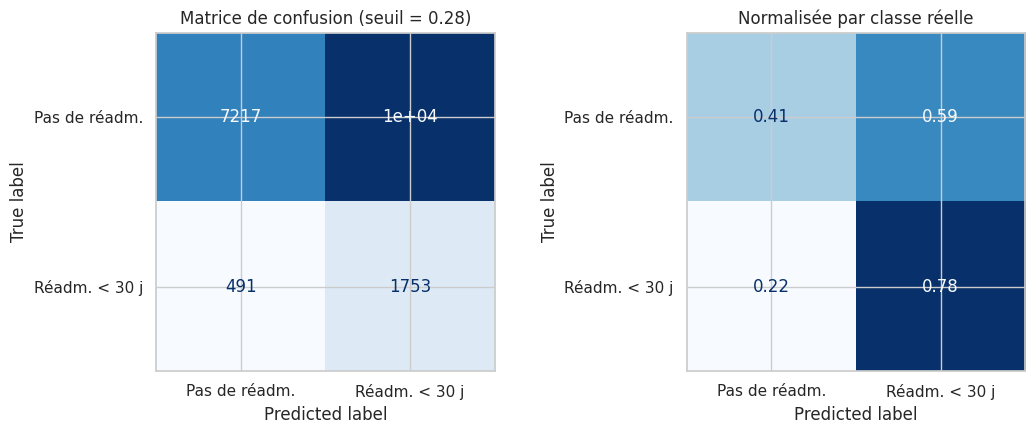

In [ ]:
s_best = scores_test[best_name]
y_pred = (s_best >= best_thr).astype(int)

perf_finale = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred)],
    "Précision": [precision_score(y_test, y_pred)],
    "Recall": [recall_score(y_test, y_pred)],
    "F1": [f1_score(y_test, y_pred)],
    "F2": [fbeta_score(y_test, y_pred, beta=2)],
    "ROC-AUC": [roc_auc_score(y_test, s_best)],
    "PR-AUC": [average_precision_score(y_test, s_best)],
    "Part des patients signalés": [y_pred.mean()],
}, index=[f"{best_name} (seuil {best_thr})"])
display(perf_finale.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
etiquettes = ["Pas de réadm.", "Réadm. < 30 j"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=etiquettes).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Matrice de confusion (seuil = {best_thr})")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"), display_labels=etiquettes).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Normalisée par classe réelle")
plt.tight_layout(); plt.show()

**Interprétation :**
- **Modèle retenu : KNN + sous-échantillonnage**, qui a la meilleure PR-AUC en validation croisée (0,196 contre 0,191). **Seuil = 0,28**, choisi sur le train.
- **Recall = 0,78** : 78 % des réadmissions du test sont détectées. **Précision = 0,145** : environ 1 patient signalé sur 7 est réellement réadmis.
- L'accuracy (0,45) est basse, ce qui est attendu : ce n'est pas le critère retenu.
- **Limite :** avec ce seuil, **61 % des patients sont signalés**, donc l'alerte est peu sélective. En pratique, l'hôpital peut plutôt **classer les patients par score** et suivre les 20 % les plus à risque, qui contiennent 37 % des réadmissions.

#### 5.2.3 Interprétation : quelles variables comptent ?

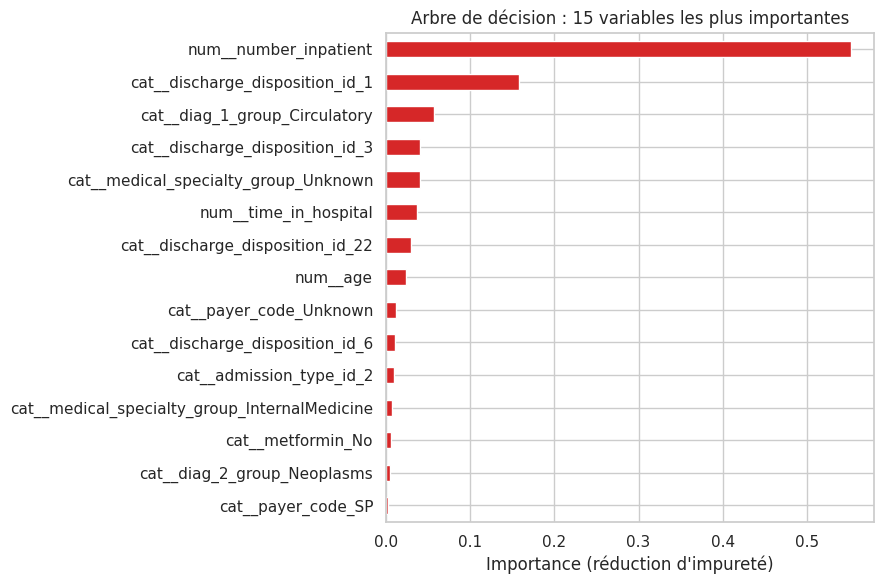

num__number_inpatient                   0.552
cat__discharge_disposition_id_1         0.158
cat__diag_1_group_Circulatory           0.056
cat__discharge_disposition_id_3         0.040
cat__medical_specialty_group_Unknown    0.040
num__time_in_hospital                   0.037
cat__discharge_disposition_id_22        0.029
num__age                                0.023
cat__payer_code_Unknown                 0.012
cat__discharge_disposition_id_6         0.011
dtype: float64


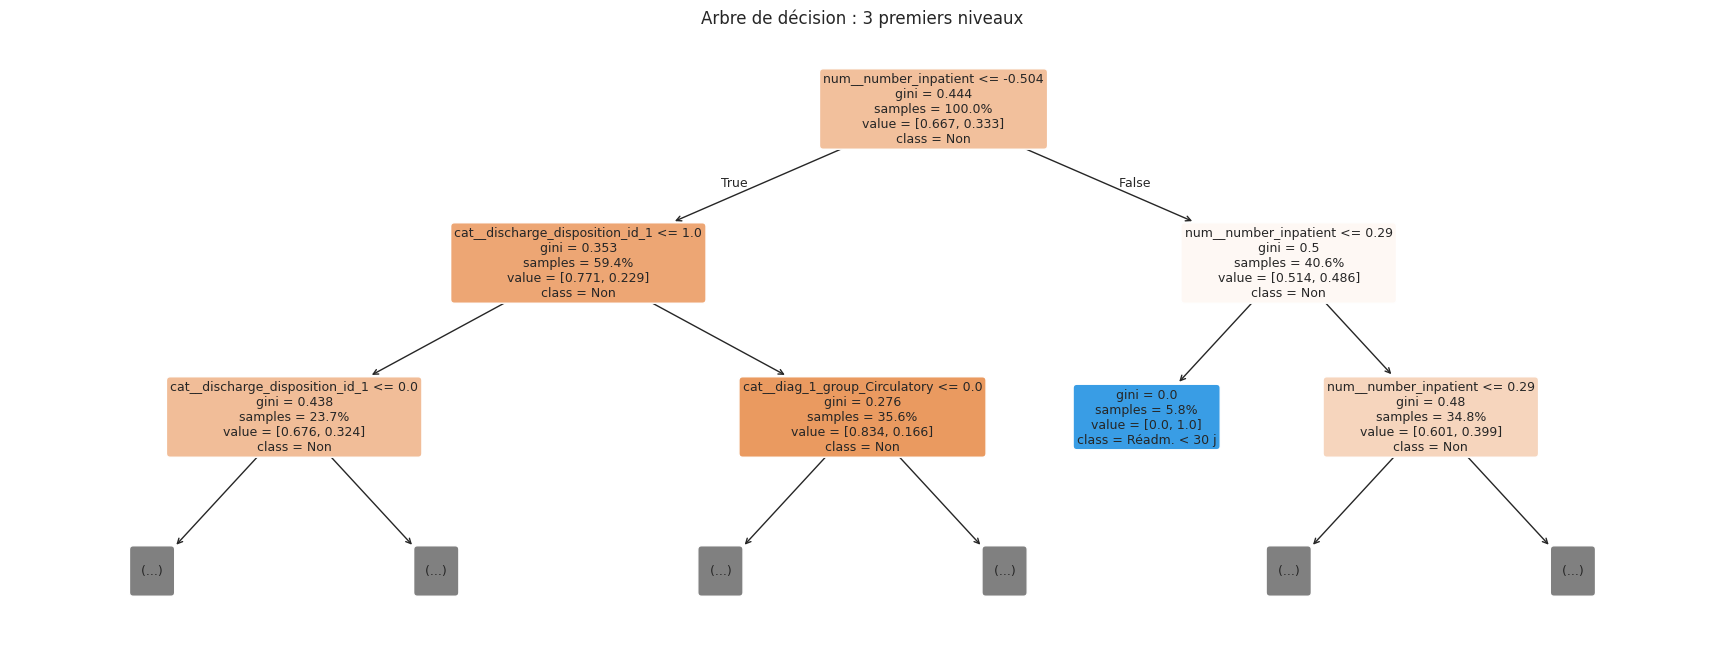

In [ ]:
from sklearn.tree import plot_tree

modele_interp = models["Arbre + SMOTE"]                 # l'arbre est interprétable (le KNN ne l'est pas)
arbre = modele_interp.estimator_
noms_variables = preprocessor_classification.get_feature_names_out()

importances = pd.Series(arbre.feature_importances_, index=noms_variables).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
importances.head(15)[::-1].plot(kind="barh", color="tab:red")
plt.title("Arbre de décision : 15 variables les plus importantes")
plt.xlabel("Importance (réduction d'impureté)")
plt.tight_layout(); plt.show()
print(importances.head(10).round(3))

plt.figure(figsize=(22, 8))
plot_tree(arbre, max_depth=2, feature_names=noms_variables, class_names=["Non", "Réadm. < 30 j"],
          filled=True, rounded=True, fontsize=9, proportion=True)
plt.title("Arbre de décision : 3 premiers niveaux")
plt.show()

**Interprétation :** on interprète l'arbre de décision, car le KNN n'a pas de règles lisibles ; ses performances sont proches de celles du KNN.
- **`number_inpatient`** (hospitalisations antérieures) domine nettement (**51 %** de l'importance) : c'est aussi la **première question** de l'arbre.
- Viennent ensuite la **sortie à domicile** (`discharge_disposition_id` = 1, 14 %), le diagnostic circulatoire, la durée du séjour et l'âge.

C'est cohérent avec l'analyse 2.13 : **l'historique d'hospitalisations est le meilleur signal disponible**. Ce sont des associations, pas des causes.

#### 5.2.4 Équité du modèle (âge, genre, origine)

Le BO1 demande de surveiller l'équité. On compare le recall de chaque groupe au recall global (alerte si l'écart dépasse 0,10). Les groupes de moins de 200 séjours ou de moins de 20 réadmissions sont exclus (trop instables).

In [ ]:
equite = X_test[["age", "gender", "race"]].reset_index(drop=True).copy()
equite["y"], equite["score"], equite["pred"] = np.asarray(y_test), s_best, y_pred
recall_global = recall_score(equite["y"], equite["pred"])
print(f"Recall global (test) : {recall_global:.3f}")

for col in ["age", "gender", "race"]:
    lignes = []
    for g, d in equite.groupby(col):
        if len(d) < 200 or d["y"].sum() < 20:
            continue
        lignes.append({col: g, "séjours": len(d), "prévalence": d["y"].mean(),
                       "ROC-AUC": roc_auc_score(d["y"], d["score"]),
                       "Recall": recall_score(d["y"], d["pred"]),
                       "Part signalée": d["pred"].mean()})
    tab = pd.DataFrame(lignes).set_index(col)
    print(f"\n=== Performance par {col} ===")
    display(tab.round(3))
    alertes = tab.index[(tab["Recall"] - recall_global).abs() > 0.10].tolist()
    print("-> ALERTE (écart de recall > 0,10) :" if alertes else "-> Aucun écart de recall > 0,10.", alertes if alertes else "")

Recall global (test) : 0.781

=== Performance par age ===


,séjours,prévalence,ROC-AUC,Recall,Part signalée
age,,,,,
[20-30),369,0.163,0.794,0.733,0.390
[30-40),757,0.115,0.700,0.678,0.398
[40-50),1909,0.096,0.659,0.601,0.403
[50-60),3467,0.109,0.695,0.737,0.483
[60-70),4356,0.116,0.646,0.766,0.600
[70-80),4921,0.113,0.625,0.826,0.702
[80-90),3284,0.121,0.605,0.897,0.808
[90-100),547,0.124,0.530,0.824,0.797


-> ALERTE (écart de recall > 0,10) : ['[30-40)', '[40-50)', '[80-90)']

=== Performance par gender ===


,séjours,prévalence,ROC-AUC,Recall,Part signalée
gender,,,,,
Female,10726,0.114,0.663,0.806,0.630
Male,9047,0.112,0.636,0.751,0.587


-> Aucun écart de recall > 0,10. 

=== Performance par race ===


,séjours,prévalence,ROC-AUC,Recall,Part signalée
race,,,,,
AfricanAmerican,3697,0.108,0.649,0.772,0.586
Caucasian,14813,0.117,0.648,0.784,0.624
Hispanic,398,0.090,0.752,0.861,0.523
Other,302,0.103,0.676,0.710,0.530
Unknown,447,0.072,0.595,0.719,0.532


-> Aucun écart de recall > 0,10. 


**Interprétation :**
- **Genre :** pas d'écart notable (recall 0,81 pour les femmes, 0,75 pour les hommes).
- **Origine :** aucun écart > 0,10 pour les groupes retenus. Les groupes Hispanic, Other et Unknown ont moins de 450 séjours : résultats peu stables.
- **Âge ⚠️ :** le recall est plus faible chez les **30-50 ans** (0,68 et 0,60) et plus élevé chez les **80-90 ans** (0,90). Le modèle signale beaucoup plus les patients âgés (81 % des 80-90 ans contre 40 % des 30-50 ans), car l'âge et l'historique de soins augmentent le score.

C'est une **limite à surveiller** avant tout usage réel.

#### 5.2.5 Verdict BO1

| Critère de succès du BO1 | Résultat | Atteint ? |
|---|---|---|
| Mieux que le hasard sur la classe minoritaire | PR-AUC 0,213 contre 0,113 ; ROC-AUC 0,65 | ✅ (gain modeste) |
| Détecter la majorité des réadmissions | Recall 0,78 au seuil 0,28 | ✅ |
| Effort concentré sur une petite part des patients | Top 20 % = 37 % des réadmissions ; au seuil choisi, 61 % des patients sont signalés | ⚠️ partiel |
| Cohérent avec la littérature | ROC-AUC 0,65 (repère 0,6 à 0,7) | ✅ |
| Équité | Pas d'écart selon le genre et l'origine ; recall plus faible chez les 30-50 ans | ⚠️ partiel |

**Décision :** le modèle est une **aide au tri** pour prioriser le suivi, pas une décision clinique.

### 5.3 Conclusion de l'évaluation et décision

| Objectif | Bilan |
|---|---|
| **BO2 — Segmentation** | **Atteint avec réserves** : 3 segments stables (ARI 0,996), interprétables et de risques différents (9,1 % / 12,7 % / 17,3 %), mais peu séparés (silhouette 0,20) |
| **BO1 — Classification** | **Atteint avec réserves** : classement meilleur que le hasard (ROC-AUC 0,65, top 20 % = 37 % des réadmissions), recall 0,78, mais précision faible (0,145) |

**Revue du processus (CRISP-DM)**
- **Ce qui garantit la validité :** séparation par patient, préprocesseur ajusté sur le train, équilibrage **dans** la validation croisée, choix du modèle et du seuil sur le train, test utilisé seulement pour mesurer.
- **Apport de l'équilibrage :** il rend le modèle capable de prédire la classe minoritaire, mais c'est le **choix du seuil** qui permet d'atteindre un recall élevé.

**Prochaines étapes**
1. Tester des modèles d'ensemble (Random Forest, gradient boosting) et une régression logistique.
2. Ajouter des variables au niveau du patient (nombre de séjours précédents dans le dataset).
3. Valider les segments et le seuil avec des cliniciens.
4. Tester une segmentation qui intègre aussi les variables catégorielles (K-Prototypes).

## 6. Deployment

### 6.1 Plan de déploiement

Le système serait utilisé **au moment de la sortie** du patient, comme **aide à la décision** :

1. **Collecte** des informations du séjour (démographie, admission, durée, actes, médicaments, diagnostics, historique).
2. **Préparation** avec exactement les mêmes transformations que dans ce notebook (préprocesseur et PCA sauvegardés).
3. **Score de risque** de réadmission à 30 jours (classifieur) et **segment** du patient (K-Means).
4. **Priorisation :** les patients au-dessus du seuil (ou dans les 20 % de scores les plus élevés) reçoivent un suivi renforcé ; le segment oriente le type de suivi.
5. **Décision finale** par l'équipe soignante : le modèle ne décide pas seul.

```
Données du séjour ──► Préprocesseur ──► Classifieur ──► Score de risque ──► Priorité de suivi
                 └──► log1p + scaler + PCA ──► K-Means ──► Segment ──► Type de parcours
```

### 6.2 Simulation sur de nouveaux séjours

On simule l'arrivée de 5 nouveaux séjours (pris dans le jeu de test) et on applique toute la chaîne.

In [ ]:
nouveaux = X_test.head(5).copy()

# 1) Classification : même préparation qu'à l'entraînement
entree_classif = nouveaux.copy()
entree_classif["age"] = entree_classif["age"].map(age_mapping)
entree_classif = preprocessor_classification.transform(entree_classif).toarray()
score_risque = best_model.predict_proba(entree_classif)[:, 1]

# 2) Segmentation : mêmes variables, log1p, standardisation et PCA
entree_seg = nouveaux[pca_vars].copy()
entree_seg["age"] = entree_seg["age"].map(age_mapping)
entree_seg[log_cols] = np.log1p(entree_seg[log_cols])
segment = kmeans_final.predict(pca.transform(scaler_pca.transform(entree_seg)))

resultat = pd.DataFrame({
    "patient": groups_test.loc[nouveaux.index].values,
    "score de risque": score_risque.round(3),
    "suivi renforcé (score >= seuil)": np.where(score_risque >= best_thr, "oui", "non"),
    "segment": segment,
    "réadmission réelle < 30 j": y_test.loc[nouveaux.index].values,
})
display(resultat)

,patient,score de risque,suivi renforcé (score >= seuil),segment,réadmission réelle < 30 j
0,114882984,0.290,oui,1,0
1,108662661,0.200,non,1,0
2,69422211,0.255,non,0,0
3,41606064,0.305,oui,0,0
4,112002975,0.185,non,1,0


In [ ]:
# Sauvegarde des objets nécessaires au déploiement
# (pour recharger le modèle ailleurs, il faut aussi définir smote, sous_echantillonnage et ModeleReequilibre)
import joblib
joblib.dump({"preprocesseur": preprocessor_classification, "modele": best_model,
             "seuil": best_thr, "age_mapping": age_mapping}, "modele_readmission.joblib")
joblib.dump({"variables": pca_vars, "log_cols": log_cols, "scaler": scaler_pca,
             "pca": pca, "kmeans": kmeans_final}, "modele_segmentation.joblib")
print("Modèles sauvegardés : modele_readmission.joblib, modele_segmentation.joblib")

Modèles sauvegardés : modele_readmission.joblib, modele_segmentation.joblib


**Interprétation :** pour ces 5 nouveaux séjours, les scores vont de **0,19 à 0,31**. **2 patients** dépassent le seuil (0,28) et recevraient un suivi renforcé, et chaque patient reçoit son segment (0 ou 1). Aucun de ces 5 patients n'a été réellement réadmis : les 2 alertes sont des **faux positifs**, ce qui illustre la précision limitée du modèle (≈ 1 alerte juste sur 7). Les modèles et le préprocesseur sont sauvegardés (`joblib`) pour être réutilisés sur de nouvelles données.

### 6.3 Maintenance et suivi

| Élément suivi | Comment | Action si dégradation |
|---|---|---|
| Performance du classifieur | Recall, PR-AUC, part des réadmissions dans le top 20 %, comparés aux réadmissions réellement observées | Réentraîner avec des données récentes |
| Dérive des données | Comparer les distributions (âge, durée de séjour, diagnostics) aux données d'entraînement | Revoir la préparation, réentraîner |
| Stabilité des segments | Taille des clusters et ARI sur les nouvelles données | Refaire le clustering |
| Équité | Recall par âge, genre et origine | Ajuster le seuil ou les données d'entraînement |

Cycle : **nouvelles données → application des modèles → suivi des performances → comparaison avec la réalité → réentraînement si nécessaire.**

## Conclusion générale

Le projet **Reditus** a suivi toutes les étapes de **CRISP-DM**.

- **Data Understanding** a révélé les manquants cachés (`?`), les variables quasi constantes, les patients répétés, les séjours non réadmissibles et le déséquilibre de la cible (11 %).
- **Data Preparation** a produit un jeu propre de **99 340 séjours** sans fuite d'information. La cible est équilibrée sur le train (SMOTE / sous-échantillonnage), et la segmentation repose sur une **PCA des 9 variables numériques** (6 composantes, 80,4 %).
- **Segmentation (BO2) :** 3 profils stables et interprétables :
  - séjours courts et légers (55,5 %, 9,1 % de réadmission) ;
  - séjours longs et lourds (30 %, 12,7 %) ;
  - usagers fréquents de l'hôpital (14,5 %, 17,3 %).
- **Classification (BO1) :** le KNN avec sous-échantillonnage atteint une **ROC-AUC de 0,65** et un **recall de 0,78**. Les 20 % de patients les plus à risque concentrent **37 %** des réadmissions. Le signal principal est le **nombre d'hospitalisations antérieures**.

Les résultats sont cohérents avec la littérature et restent une **aide à la décision** : ils doivent être validés par des cliniciens avant tout usage réel.